In [1]:
import scanpy as sc

In [3]:
!ls /n/netscratch/eddy_lab/Everyone/nhilgert/

20251008_Cevrim_Human_All_Cells.h5ad
20251008_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
20251008_Cevrim_XMens_All_Cells.h5ad
20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
2026_08_28_Cevrim_Human_All_Cells.h5ad
2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
2026_08_28_Cevrim_XMens_All_Cells.h5ad
2026_08_28_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
2026_09_02_samap_raw_all.h5ad
donttouch
heca
stro7_margin.csv


In [4]:
adata = sc.read_h5ad("/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad")

In [5]:
adata

AnnData object with n_obs × n_vars = 47533 × 36601
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'lineage', 'cell_type', 'subtype', 'annotation_level', 'x_um_dbscan', 'y_um_dbscan', 'cell_subtype', 'stro7_margin', 'dpt_pseudotime', 'dpt_pseudotime_provenance', 'x_um_qc', 'y_um_qc', 'spatial_qc_reason', 'tissue_section'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'annotation_level_colors', 'annotation_schema_version', 'display_names', 'embedding_provenance', 'embedding_provenance_note', 'hvg', 'label_colors', 'label_relabel', 'log1p', 'neighbors_scVI_100', 'spatial_outlier_fix', 'spatial_qc_push', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_scVI_wholetissue', 'X_spatial', 'X_umap_scVI', 'X_umap_wholetissue'
    layers: 'counts'

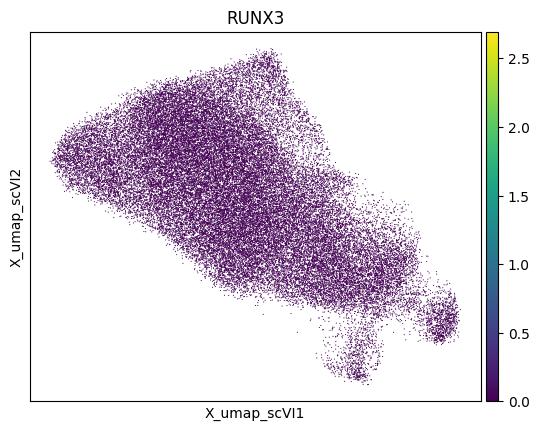

In [9]:
sc.pl.embedding(adata, basis = 'X_umap_scVI', color = 'RUNX3')

In [7]:
from gpu_utils import *

gpu_utils: rapids-singlecell loaded. GPU acceleration enabled


47,533 cells | leiden_0.5: 6 clusters | leiden_0.8: 8 clusters | leiden_1.0: 10 clusters | leiden_1.2: 11 clusters
plottable: 33,250 (70%); by phase menstrual 60%, secretory 80%


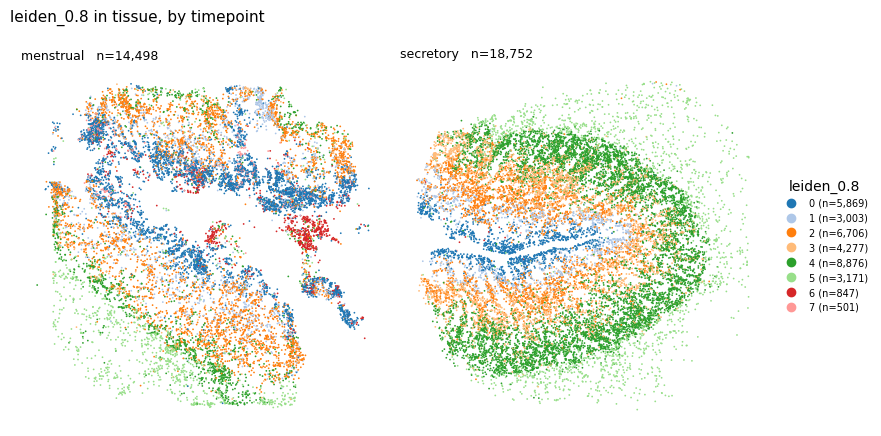

In [14]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

P = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud/fib_cluster_labels_spatial.csv")
lab = pd.read_csv(P, index_col=0)
lab.index = lab.index.astype(str)

RES = [c for c in lab.columns if c.startswith("leiden_")]
for c in RES:
    lab[c] = lab[c].astype(str)
print(f"{len(lab):,} cells | " + " | ".join(f"{c}: {lab[c].nunique()} clusters" for c in RES))

# 30% of nuclei have no Slide-tags coordinate — they are dropped for plotting only
xy = lab[["x_um_dbscan", "y_um_dbscan"]].notna().all(axis=1)
print(f"plottable: {xy.sum():,} ({xy.mean():.0%}); "
      f"by phase " + ", ".join(f"{k} {v:.0%}" for k, v in
                               xy.groupby(lab.timepoint).mean().items()))

def plot_clusters(res="leiden_0.8", facet="timepoint", s=1.6, ncol=None):
    """One spatial panel per facet level, points coloured by cluster."""
    d = lab[xy]
    groups = sorted(d[facet].astype(str).unique())
    n = len(groups); ncol = ncol or n
    nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 4.6 * nrow), squeeze=False)
    cl = sorted(d[res].unique(), key=lambda x: int(x))
    cmap = plt.get_cmap("tab20")
    colors = {c: cmap(i % 20) for i, c in enumerate(cl)}
    rng = np.random.default_rng(0)
    for k, g in enumerate(groups):
        ax = axs[k // ncol][k % ncol]
        sub = d[d[facet].astype(str) == g]
        o = rng.permutation(len(sub))          # shuffle so no cluster is drawn on top
        ax.scatter(sub.x_um_dbscan.values[o], sub.y_um_dbscan.values[o],
                   c=[colors[v] for v in sub[res].values[o]], s=s, linewidths=0,
                   rasterized=True)
        ax.set_title(f"{g}   n={len(sub):,}", fontsize=9, loc="left")
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values(): sp.set_visible(False)
    for k in range(n, nrow * ncol):
        axs[k // ncol][k % ncol].axis("off")
    handles = [plt.Line2D([], [], marker="o", ls="", ms=6, color=colors[c],
                          label=f"{c} (n={(d[res] == c).sum():,})") for c in cl]
    axs[0][-1].legend(handles=handles, fontsize=7, frameon=False,
                      loc="center left", bbox_to_anchor=(1.02, 0.5), title=res)
    fig.suptitle(f"{res} in tissue, by {facet}", x=0.005, ha="left", fontsize=11)
    fig.tight_layout()
    return fig

fig = plot_clusters("leiden_0.8")
fig.savefig("leiden_0.8_spatial.png", dpi=300, bbox_inches="tight")

In [15]:
# Join the leiden labels onto adata.obs. Checks the barcode overlap rather than assuming it:
# these objects have not always shared a barcode convention, and a silent partial join would
# quietly drop cells from every downstream plot.
RES = [c for c in lab.columns if c.startswith("leiden_")]

adata.obs_names = adata.obs_names.astype(str)
lab.index = lab.index.astype(str)
ov = adata.obs_names.intersection(lab.index)
print(f"adata {adata.n_obs:,} cells | label table {len(lab):,} | overlap {len(ov):,}")
assert len(ov) == adata.n_obs, (
    f"only {len(ov):,}/{adata.n_obs:,} barcodes matched — check the barcode convention.\n"
    f"  adata: {list(adata.obs_names[:2])}\n  labels: {list(lab.index[:2])}")

for c in RES + ["sample", "donor", "timepoint"]:
    if c in lab.columns:
        adata.obs[c] = pd.Categorical(lab[c].reindex(adata.obs_names).astype(str))
for c in ["x_um_dbscan", "y_um_dbscan"]:
    if c in lab.columns:
        adata.obs[c] = lab[c].reindex(adata.obs_names).values

# order the cluster categories numerically, not lexically (else c10 sorts before c2)
for c in RES:
    adata.obs[c] = adata.obs[c].cat.reorder_categories(
        sorted(adata.obs[c].cat.categories, key=int), ordered=True)

print("\nadded:", RES)
for c in RES:
    print(f"  {c}: {adata.obs[c].nunique()} clusters -> "
          f"{adata.obs[c].value_counts().sort_index().to_dict()}")

adata 47,533 cells | label table 47,533 | overlap 47,533

added: ['leiden_0.5', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2']
  leiden_0.5: 6 clusters -> {'0': 9383, '1': 11103, '2': 20555, '3': 4657, '4': 791, '5': 1044}
  leiden_0.8: 8 clusters -> {'0': 8220, '1': 4207, '2': 9967, '3': 5056, '4': 12220, '5': 5882, '6': 1235, '7': 746}
  leiden_1.0: 10 clusters -> {'0': 7913, '1': 8945, '2': 4245, '3': 747, '4': 7735, '5': 1231, '6': 6042, '7': 4185, '8': 5712, '9': 778}
  leiden_1.2: 11 clusters -> {'0': 7943, '1': 8065, '2': 879, '3': 4332, '4': 801, '5': 5786, '6': 6513, '7': 1270, '8': 5684, '9': 5512, '10': 748}


Stro-2: not in adata.var_names -> ['C10orf10']
Stro-9: not in adata.var_names -> ['CTD-3252C9.4']
X is already log-normalised; using it directly


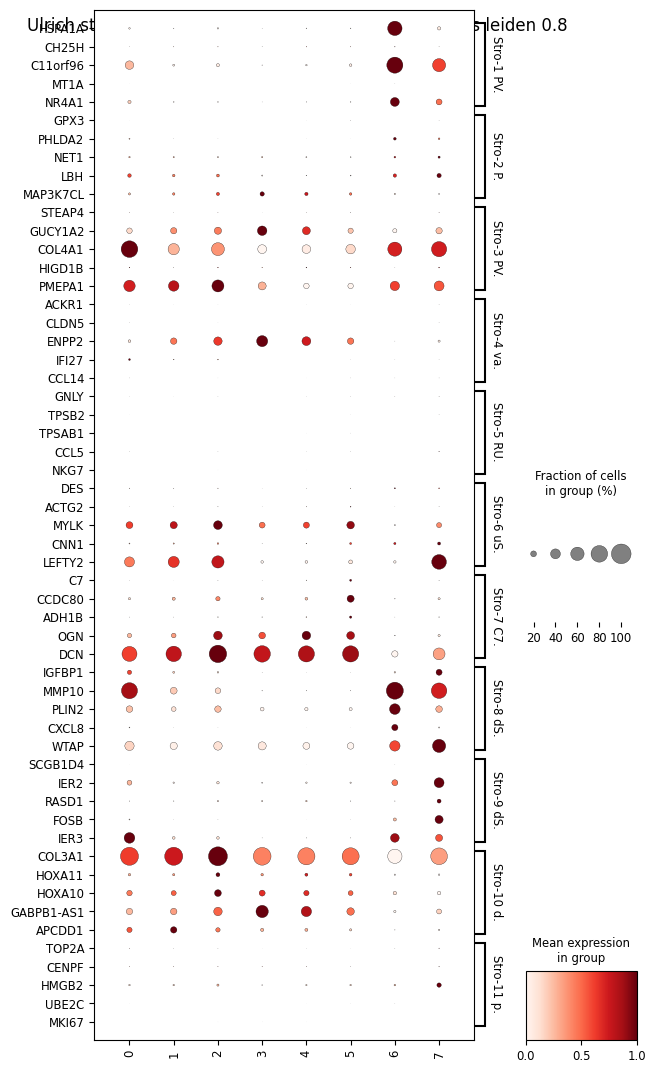

In [16]:
import scanpy as sc, numpy as np, pandas as pd
from pathlib import Path

# Marker panels come from Ulrich's own S5B centroids ranked by specificity margin — expression in
# a subtype minus its highest expression in any OTHER stromal subtype. NOT from their published DE
# list, which omits IGFBP1/MMP10/MMP3 (the three most dS1-specific centroid genes).
SPEC = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud/"
            "fib_summary_tables/hammoud_stromal_marker_specificity_full.csv")
M = pd.read_csv(SPEC)

N_PER = 5
SNUM = lambda s: int(str(s).split("-")[1])
LBL = {1: "PV FOXC1hi", 2: "PV FOXC1lo", 3: "PV STEAP4", 4: "vasc. prog.",
       5: "RUNX3+ (immune)", 6: "uSMC", 7: "C7 fib", 8: "dS1", 9: "dS2", 10: "dS3",
       11: "progenitor"}

panels, missing = {}, {}
for n in range(1, 12):
    d = (M[M.subtype == f"Stro-{n}"]
         .sort_values("margin_stromal", ascending=False))
    genes = [g for g in d.gene if g in adata.var_names][:N_PER]
    missing[n] = [g for g in d.gene.head(N_PER) if g not in adata.var_names]
    panels[f"Stro-{n} {LBL[n]}"] = genes
for n, g in missing.items():
    if g:
        print(f"Stro-{n}: not in adata.var_names -> {g}")

# use a log-normalised matrix without modifying adata.X in place
if float(adata.X.max()) > 50:
    adata.layers["lognorm"] = adata.X.copy()
    sc.pp.normalize_total(adata, target_sum=1e4, layer="lognorm")
    sc.pp.log1p(adata, layer="lognorm")
    LAYER = "lognorm"
    print("X looked like counts -> built a 'lognorm' layer (adata.X untouched)")
else:
    LAYER = None
    print("X is already log-normalised; using it directly")

sc.pl.dotplot(
    adata, panels, groupby="leiden_0.8", layer=LAYER,
    standard_scale="var",          # scale each GENE 0-1 across clusters, so specificity is visible
    swap_axes=True, dendrogram=False, cmap="Reds",
    figsize=(7, 13),
    title="Ulrich stromal markers (top 5 by specificity margin) vs leiden 0.8",
    save="_stromal_markers_leiden08.png",
)

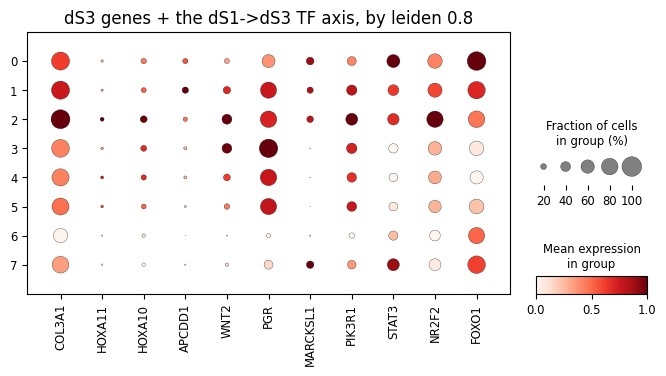

n cells: c1=4,207  c2=9,967  other=33,359

          c1_mean  c2_mean  other  c1_pct  c2_pct  c1_over_c2 higher_in
COL3A1      2.411    2.734  2.057  89.565  95.375        0.88        c2
HOXA11      0.079    0.149  0.095   5.586  11.689        0.53        c2
HOXA10      0.245    0.348  0.251  16.259  24.601        0.71        c2
APCDD1      0.429    0.202  0.143  22.439  13.505        2.13        c1
WNT2        0.440    0.620  0.350  27.264  40.534        0.71        c2
PGR         1.975    1.873  1.765  76.943  79.141        1.05        c1
MARCKSL1    0.341    0.323  0.110  21.892  23.488        1.06        c1
PIK3R1      0.782    0.907  0.657  42.358  51.510        0.86        c2
STAT3       0.788    0.803  0.679  45.424  49.032        0.98        c2
NR2F2       1.262    1.553  1.053  64.749  78.379        0.81        c2
FOXO1       2.503    2.101  1.873  84.930  80.144        1.19        c1

genes higher in c1: 4/11


In [17]:
# dS3 has ZERO genes clearing a 0.5 specificity margin in Ulrich's own centroids (best is COL3A1
# at +0.34), so its "markers" are canonical stromal identity genes at graded levels. Expect a
# gradient between c1 and c2, not a clean split — and read the TF axis, which is what the paper
# actually separates dS1/dS2/dS3 by: STAT3 falling, HOXA10/NR2F2 rising toward dS3.
DS3   = ["COL3A1", "HOXA11", "HOXA10", "APCDD1", "WNT2", "PGR", "MARCKSL1", "PIK3R1"]
AXIS  = ["STAT3", "HOXA10", "HOXA11", "NR2F2", "PGR", "FOXO1"]
genes = [g for g in dict.fromkeys(DS3 + AXIS) if g in adata.var_names]

sc.pl.dotplot(adata, genes, groupby="leiden_0.8", layer=LAYER,
              standard_scale="var", cmap="Reds", figsize=(8, 3.4),
              title="dS3 genes + the dS1->dS3 TF axis, by leiden 0.8",
              save="_dS3_axis_leiden08.png")

# the numeric c1 vs c2 comparison, with the rest of the tissue as a reference
X = adata[:, genes].layers[LAYER] if LAYER else adata[:, genes].X
X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)
E = pd.DataFrame(X, index=adata.obs_names, columns=genes)
cl = adata.obs["leiden_0.8"].astype(str)

out = pd.DataFrame({
    "c1_mean":   E[cl == "1"].mean(),
    "c2_mean":   E[cl == "2"].mean(),
    "other":     E[~cl.isin(["1", "2"])].mean(),
    "c1_pct":    100 * (E[cl == "1"] > 0).mean(),
    "c2_pct":    100 * (E[cl == "2"] > 0).mean(),
})
out["c1_over_c2"] = (out.c1_mean / out.c2_mean).round(2)
out["higher_in"] = np.where(out.c1_mean > out.c2_mean, "c1", "c2")
print(f"n cells: c1={int((cl=='1').sum()):,}  c2={int((cl=='2').sum()):,}  "
      f"other={int((~cl.isin(['1','2'])).sum()):,}\n")
print(out.round(3).to_string())
print(f"\ngenes higher in c1: {int((out.higher_in=='c1').sum())}/{len(out)}")

In [18]:
import numpy as np, pandas as pd, scipy.sparse as sp
from pathlib import Path
from sklearn.preprocessing import normalize

HAM   = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud")
SD05  = HAM / "pnas.2404775121.sd05.xlsx"
GROUP = "leiden_0.8"
SUBT  = "Stro-10_dS3"
N_PANEL = 3000                      # the published run's panel size, from run_config.txt
EXPECTED = {"1": 0.2998, "2": 0.2940}   # from cosine_11stromal_leiden_0.8.csv

# --- atlas centroids, all 11 stromal columns -------------------------------------------
A = pd.ExcelFile(SD05).parse("5B Subtype centroids", header=2, index_col=0)
A.columns = pd.Index(A.columns).astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
A.index   = A.index.astype(str).str.strip()
A = A[~A.index.isin(["nan", ""])].apply(pd.to_numeric, errors="coerce")
A = A[~A.index.duplicated(keep="first")].dropna(how="all")
STRO = sorted([c for c in A.columns if c.startswith("Stro-")],
              key=lambda s: int(s.split("-")[1].split("_")[0]))
assert len(STRO) == 11 and SUBT in STRO

# --- our cluster centroids, in the PIPELINE'S convention -------------------------------
# average in LINEAR CP10K space, then log1p (a pseudobulk). This is NOT the mean of the
# per-cell log1p values — the stored cluster_centroids.parquet satisfies sum(expm1)=1e4 per
# column, which identifies it as log-of-mean. Getting this wrong shifts every score.
Xl = adata.layers[LAYER] if LAYER else adata.X
cl = adata.obs[GROUP].astype(str)
cents = {}
for c in sorted(cl.unique(), key=int):
    blk = Xl[(cl == c).values]
    blk = blk.toarray() if sp.issparse(blk) else np.asarray(blk)
    cents[c] = np.log1p(np.expm1(blk).mean(axis=0)).ravel()
Q = pd.DataFrame(cents, index=adata.var_names.astype(str))

# --- shared genes and the variance panel, selected over the 11 columns being discriminated
shared = Q.index.intersection(A.index)
panel  = A.loc[shared, STRO].var(axis=1).nlargest(N_PANEL).index
print(f"shared genes {len(shared):,} | panel {len(panel):,}")

# --- centre each side per gene within itself, L2-normalise each column ------------------
Qp, Ap = Q.loc[panel], A.loc[panel, STRO]
Qc = Qp.sub(Qp.mean(axis=1), axis=0)
Ac = Ap.sub(Ap.mean(axis=1), axis=0)
Qn = pd.DataFrame(normalize(Qc.T.fillna(0), axis=1).T, index=panel, columns=Qp.columns)
An = pd.DataFrame(normalize(Ac.T.fillna(0), axis=1).T, index=panel, columns=STRO)

# --- per-gene contributions: they SUM to the cosine, exactly ---------------------------
contrib = pd.DataFrame({c: Qn[c] * An[SUBT] for c in Qn.columns}, index=panel)
print(f"\n{SUBT} cosine, recomputed as the sum of per-gene contributions:")
for c, exp in EXPECTED.items():
    got = contrib[c].sum()
    print(f"  c{c}: {got:+.4f}   stored {exp:+.4f}   diff {got-exp:+.5f}"
          f"   {'OK' if abs(got-exp) < 0.01 else 'MISMATCH — check LAYER/normalisation'}")

shared genes 33,791 | panel 3,000

Stro-10_dS3 cosine, recomputed as the sum of per-gene contributions:
  c1: +0.2998   stored +0.2998   diff +0.00001   OK
  c2: +0.2940   stored +0.2940   diff -0.00002   OK


c1:   59 genes reach 50% of the cosine (2.0% of the panel)
c1:  206 genes reach 90% of the cosine (6.9% of the panel)
c2:   51 genes reach 50% of the cosine (1.7% of the panel)
c2:  187 genes reach 90% of the cosine (6.2% of the panel)

top 25 drivers shared between c1 and c2: 16/25
          contrib_c1  contrib_c2  atlas_centred  our_c1_centred  our_c2_centred
SFRP4        -0.0008      0.0096         1.8622         -0.0578          0.5293
MMP11         0.0069      0.0086         1.3486          0.6654          0.6567
DIO2          0.0076      0.0068         0.9640          1.0231          0.7246
VCAN          0.0067      0.0037         0.9829          0.8885          0.3888
C11orf96      0.0059      0.0063        -1.3539         -0.5695         -0.4766
LUM           0.0031      0.0057         0.8354          0.4801          0.7014
HSPA1A        0.0052      0.0054        -1.6522         -0.4061         -0.3374
RORB          0.0050      0.0019         0.7767          0.8324          0.2

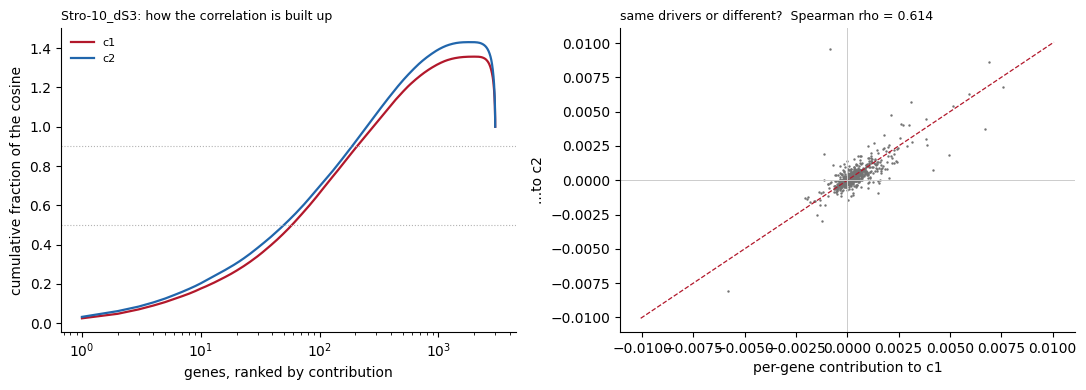

In [19]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

# how concentrated is the signal?
ax = axs[0]
for c, col in [("1", "#b2182b"), ("2", "#2166ac")]:
    s = contrib[c].sort_values(ascending=False)
    frac = s.cumsum() / s.sum()
    ax.plot(np.arange(1, len(frac) + 1), frac.values, color=col, lw=1.6, label=f"c{c}")
    for target in (0.5, 0.9):
        n = int((frac < target).sum()) + 1
        print(f"c{c}: {n:>4d} genes reach {target:.0%} of the cosine "
              f"({n/len(frac):.1%} of the panel)")
ax.axhline(0.5, color="0.7", lw=.8, ls=":"); ax.axhline(0.9, color="0.7", lw=.8, ls=":")
ax.set_xscale("log"); ax.set_xlabel("genes, ranked by contribution")
ax.set_ylabel("cumulative fraction of the cosine")
ax.set_title(f"{SUBT}: how the correlation is built up", fontsize=9, loc="left")
ax.legend(fontsize=8, frameon=False)
for sp_ in ("top", "right"): ax.spines[sp_].set_visible(False)

# do c1 and c2 score high on the SAME genes, or different ones?
ax = axs[1]
ax.scatter(contrib["1"], contrib["2"], s=3, c="0.45", linewidths=0, rasterized=True)
lim = np.abs(contrib[["1", "2"]].values).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color="#b2182b", lw=.9, ls="--")
ax.axhline(0, color="0.8", lw=.7); ax.axvline(0, color="0.8", lw=.7)
r = contrib["1"].corr(contrib["2"], method="spearman")
ax.set_xlabel("per-gene contribution to c1"); ax.set_ylabel("...to c2")
ax.set_title(f"same drivers or different?  Spearman rho = {r:.3f}", fontsize=9, loc="left")
for sp_ in ("top", "right"): ax.spines[sp_].set_visible(False)
fig.tight_layout()

# the top drivers, and whether they are shared
TOP = 25
t1 = set(contrib["1"].nlargest(TOP).index); t2 = set(contrib["2"].nlargest(TOP).index)
print(f"\ntop {TOP} drivers shared between c1 and c2: {len(t1 & t2)}/{TOP}")
tbl = pd.DataFrame({
    "contrib_c1": contrib["1"], "contrib_c2": contrib["2"],
    "atlas_centred": Ac[SUBT], "our_c1_centred": Qc["1"], "our_c2_centred": Qc["2"],
}).loc[sorted(t1 | t2, key=lambda g: -contrib.loc[g, ["1", "2"]].max())]
print(tbl.round(4).to_string())

In [20]:
sign_atlas = np.sign(Ac[SUBT])
split = {}
for c in ("1", "2"):
    ctr = contrib[c]
    pos_pos = ctr[(sign_atlas > 0) & (Qc[c] > 0)].sum()
    neg_neg = ctr[(sign_atlas < 0) & (Qc[c] < 0)].sum()
    disagree = ctr[np.sign(Ac[SUBT]) != np.sign(Qc[c])].sum()
    split[f"c{c}"] = dict(total=ctr.sum(), shared_presence=pos_pos,
                          shared_absence=neg_neg, disagreement=disagree,
                          pct_from_absence=100 * neg_neg / (pos_pos + neg_neg))
print(pd.DataFrame(split).round(4).to_string())

# which genes actually separate c1 from c2?
d = (contrib["1"] - contrib["2"]).sort_values()
sep = pd.DataFrame({"contrib_c1": contrib["1"], "contrib_c2": contrib["2"],
                    "diff_c1_minus_c2": contrib["1"] - contrib["2"],
                    "atlas_centred": Ac[SUBT]})
print("\nmost c2-specific drivers:"); print(sep.loc[d.index[:12]].round(4).to_string())
print("\nmost c1-specific drivers:"); print(sep.loc[d.index[-12:]].round(4).to_string())

                       c1       c2
total              0.2998   0.2940
shared_presence    0.2450   0.2610
shared_absence     0.1618   0.1595
disagreement      -0.1069  -0.1265
pct_from_absence  39.7715  37.9316

most c2-specific drivers:
         contrib_c1  contrib_c2  diff_c1_minus_c2  atlas_centred
SFRP4       -0.0008      0.0096           -0.0104         1.8622
COL1A1      -0.0011      0.0019           -0.0031         0.9787
COL3A1       0.0021      0.0048           -0.0026         1.0628
LUM          0.0031      0.0057           -0.0026         0.8354
PTCH1       -0.0007      0.0011           -0.0018         0.5540
MMP11        0.0069      0.0086           -0.0017         1.3486
GJA1         0.0018      0.0033           -0.0015         0.6182
MT2A         0.0026      0.0041           -0.0015        -1.1478
SFRP1        0.0010      0.0025           -0.0015         0.8239
COL1A2      -0.0000      0.0014           -0.0014         0.7119
DCN          0.0013      0.0027           -0.001

In [21]:
ECM = {"COL1A1","COL1A2","COL3A1","COL5A1","COL5A2","COL6A1","COL6A2","COL6A3","COL14A1",
       "LUM","DCN","SFRP1","SFRP2","SFRP4","MMP11","FBLN1","FBLN2","VCAN","POSTN","BGN",
       "ASPN","OGN","MGP","DPT","CCDC80","SPARC","FN1","ELN","APCDD1","PTCH1","GJA1"}
SMC = {"ACTA2","TAGLN","MYH11","CNN1","MYL9","DES","ACTG2","LMOD1"}
STRESS = {g for g in panel if g.startswith(("HSP","DNAJ","MT2","JUN","FOS","EGR","ZFP36",
                                            "NR4A","GEM","SOCS3","IER","ATF3","KLF"))}
MITO = {g for g in panel if g.startswith(("MT-","MTRNR"))}

cls = pd.Series("other", index=panel)
for name, S in [("ECM/matrix", ECM), ("smooth muscle", SMC),
                ("stress/IEG", STRESS), ("mitochondrial", MITO)]:
    cls[[g for g in panel if g in S]] = name

for c in ("1", "2"):
    t = contrib[c].groupby(cls).agg(total="sum", n="size")
    t["pct_of_cosine"] = (100 * t.total / contrib[c].sum()).round(1)
    print(f"\n--- c{c}  (cosine {contrib[c].sum():.4f}) ---")
    print(t.sort_values("total", ascending=False).round(4).to_string())

diff = (contrib["1"] - contrib["2"]).groupby(cls).sum().sort_values()
print("\nc1 minus c2, by gene class (negative = favours c2):")
print(diff.round(4).to_string())


--- c1  (cosine 0.2998) ---
                total     n  pct_of_cosine
other          0.2285  2892           76.2
stress/IEG     0.0472    54           15.8
ECM/matrix     0.0211    31            7.1
mitochondrial  0.0098    15            3.3
smooth muscle -0.0070     8           -2.3

--- c2  (cosine 0.2940) ---
                total     n  pct_of_cosine
other          0.2120  2892           72.1
stress/IEG     0.0508    54           17.3
ECM/matrix     0.0465    31           15.8
mitochondrial -0.0010    15           -0.3
smooth muscle -0.0144     8           -4.9

c1 minus c2, by gene class (negative = favours c2):
ECM/matrix      -0.0254
stress/IEG      -0.0036
smooth muscle    0.0075
mitochondrial    0.0108
other            0.0165


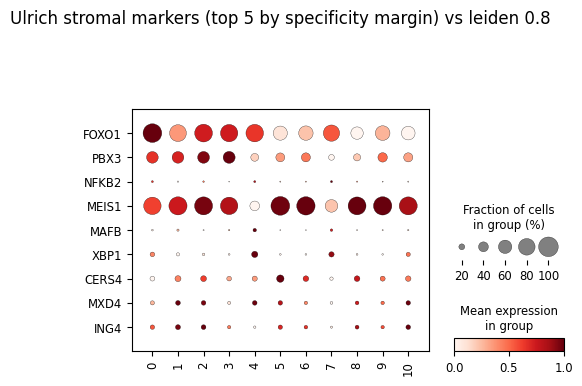

In [40]:
sc.pl.dotplot(
    adata, ["FOXO1","PBX3", "NFKB2", "MEIS1", "MAFB", "XBP1", "CERS4", "MXD4", "ING4"], groupby="leiden_1.2", layer=LAYER,
    standard_scale="var",          # scale each GENE 0-1 across clusters, so specificity is visible
    swap_axes=True, dendrogram=False, cmap="Reds",
  #  figsize=(7, 13),
    title="Ulrich stromal markers (top 5 by specificity margin) vs leiden 0.8",
    save="_stromal_markers_leiden08.png",
)

In [27]:
adata.obs.columns

Index(['sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined',
       'origin_lineage', 'lineage', 'cell_type', 'subtype', 'annotation_level',
       'x_um_dbscan', 'y_um_dbscan', 'cell_subtype', 'stro7_margin',
       'dpt_pseudotime', 'dpt_pseudotime_provenance', 'x_um_qc', 'y_um_qc',
       'spatial_qc_reason', 'tissue_section', 'leiden_0.5', 'leiden_0.8',
       'leiden_1.0', 'leiden_1.2', 'donor'],
      dtype='object')

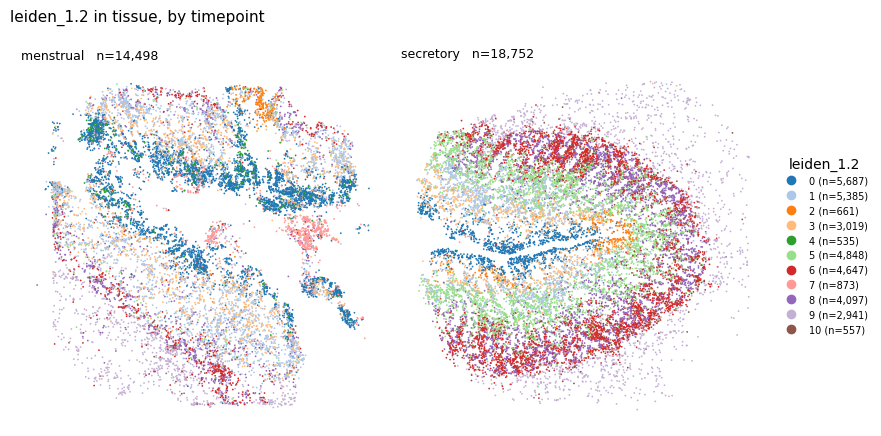

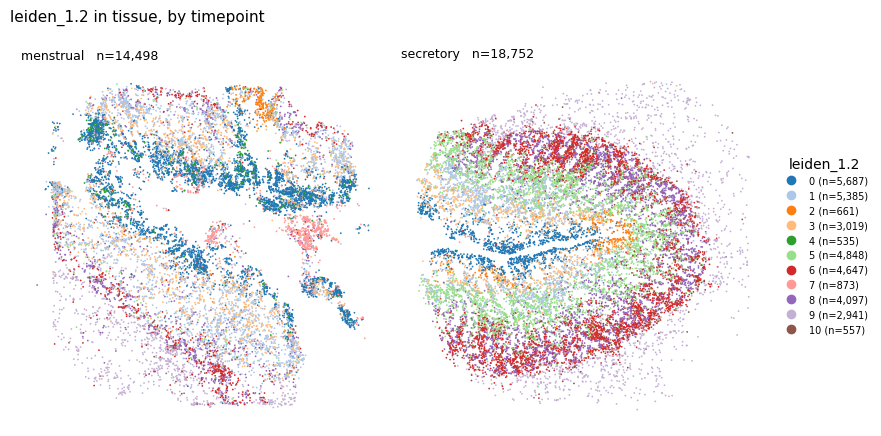

In [29]:
plot_clusters("leiden_1.2")


In [31]:
import numpy as np, pandas as pd

pt = adata.obs['dpt_pseudotime'].astype(float)
ok = np.isfinite(pt)                      # excludes NaN and inf

ranks = pt[ok].rank(method='average') / ok.sum()
adata.obs['dpt_pseudotime_rank_normalized'] = ranks.reindex(adata.obs_names)

print(f"{ok.sum():,} / {adata.n_obs:,} cells ranked; "
      f"range {ranks.min():.4f}–{ranks.max():.4f}")

47,533 / 47,533 cells ranked; range 0.0000–1.0000


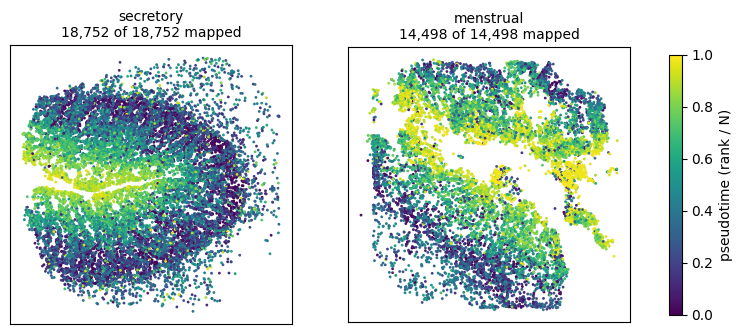

In [32]:
import matplotlib.pyplot as plt

obs = adata.obs
has_xy = obs[['x_um_dbscan', 'y_um_dbscan']].notna().all(axis=1)
tps = obs['timepoint'].astype(str)
levels = list(pd.unique(tps))

fig, axes = plt.subplots(1, len(levels), figsize=(5 * len(levels), 5.2), squeeze=False)
for ax, tp in zip(axes.ravel(), levels):
    sub = obs[has_xy & (tps == tp)]
    # all mapped cells in grey, so the tissue outline is visible under the subset
    ax.scatter(sub['x_um_dbscan'], sub['y_um_dbscan'],
               s=2, c='0.88', linewidths=0, rasterized=True)

    v = sub['dpt_pseudotime_rank_normalized']
    m = v.notna()
    pts = ax.scatter(sub.loc[m, 'x_um_dbscan'], sub.loc[m, 'y_um_dbscan'],
                     c=v[m], s=4, cmap='viridis', vmin=0, vmax=1,
                     linewidths=0, rasterized=True)

    ax.set_aspect('equal')
    ax.set_title(f"{tp}\n{m.sum():,} of {len(sub):,} mapped", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

fig.colorbar(pts, ax=axes.ravel().tolist(), shrink=0.65,
             label='pseudotime (rank / N)')

In [33]:
adata.write_h5ad("/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad")

using .X
47,533 cells, 1187–1189 per bin


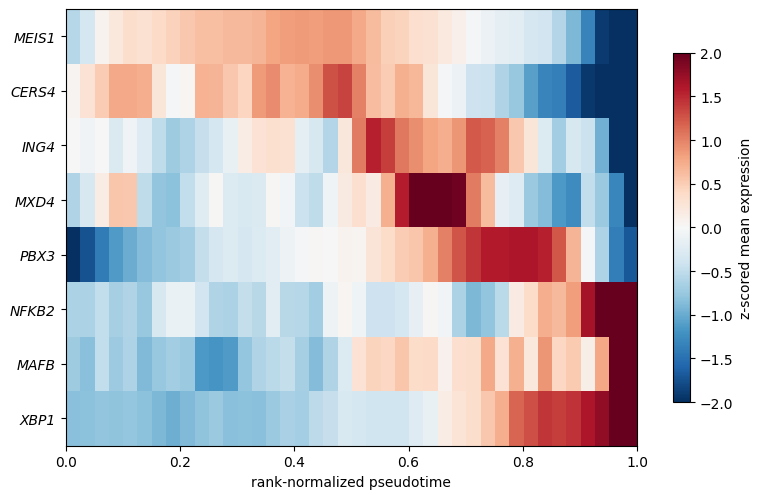

In [34]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import issparse

genes = ["PBX3", "NFKB2", "MEIS1", "MAFB", "XBP1", "CERS4", "MXD4", "ING4"]
n_bins, order_by_peak = 40, True

# .X on the deposited objects is raw counts — point at the log1p layer if it's there
layer = 'log1p' if 'log1p' in adata.layers else None
print(f"using {'layers[log1p]' if layer else '.X'}")

missing = [g for g in genes if g not in adata.var_names]
if missing:
    print("not in var_names:", missing)
genes = [g for g in genes if g in adata.var_names]

pt = adata.obs['dpt_pseudotime_rank_normalized']
keep = pt.notna()

sub = adata[keep.values, genes]
X = sub.layers[layer] if layer else sub.X
X = X.toarray() if issparse(X) else np.asarray(X)

df = pd.DataFrame(X, columns=genes)
df['bin'] = np.clip((pt[keep].to_numpy() * n_bins).astype(int), 0, n_bins - 1)

counts = df.groupby('bin').size().reindex(range(n_bins), fill_value=0)
print(f"{keep.sum():,} cells, {counts.min()}–{counts.max()} per bin")

prof = df.groupby('bin')[genes].mean().reindex(range(n_bins)).interpolate()
prof = prof.rolling(3, center=True, min_periods=1).mean()          # light smoothing
z = ((prof - prof.mean()) / prof.std(ddof=0)).T                    # genes x bins

if order_by_peak:
    z = z.iloc[np.argsort(np.nanargmax(z.to_numpy(), axis=1))]

fig, ax = plt.subplots(figsize=(8, 0.45 * len(z) + 1.5))
im = ax.imshow(z.to_numpy(), aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2,
               extent=[0, 1, len(z), 0], interpolation='nearest')
ax.set_yticks(np.arange(len(z)) + 0.5)
ax.set_yticklabels(z.index, style='italic')
ax.set_xlabel('rank-normalized pseudotime')
fig.colorbar(im, ax=ax, shrink=0.8, label='z-scored mean expression')
plt.tight_layout()

47,533 cells | 475–476 per bin | 0 empty


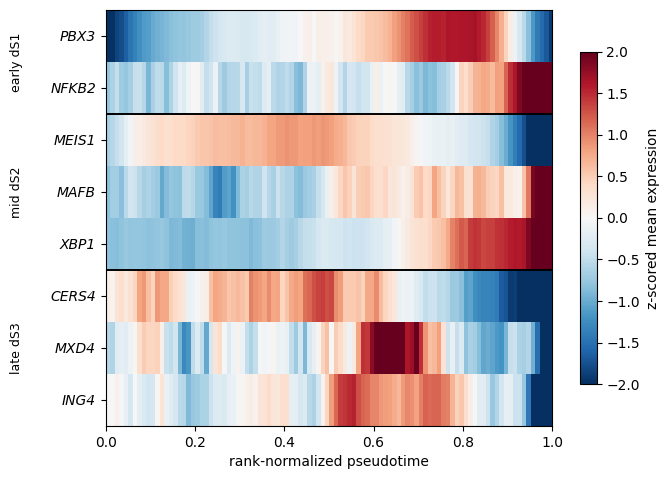

In [35]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import issparse

groups = {
    'early dS1': ["PBX3", "NFKB2"],
    'mid dS2':   ["MEIS1", "MAFB", "XBP1"],
    'late dS3':  ["CERS4", "MXD4", "ING4"],
}
n_bins, smooth = 100, 7

layer = 'log1p' if 'log1p' in adata.layers else None
groups = {k: [g for g in v if g in adata.var_names] for k, v in groups.items()}
genes = [g for v in groups.values() for g in v]

pt = adata.obs['dpt_pseudotime_rank_normalized']
keep = pt.notna()

sub = adata[keep.values, genes]
X = sub.layers[layer] if layer else sub.X
df = pd.DataFrame(X.toarray() if issparse(X) else np.asarray(X), columns=genes)
df['bin'] = np.clip((pt[keep].to_numpy() * n_bins).astype(int), 0, n_bins - 1)

counts = df.groupby('bin').size().reindex(range(n_bins), fill_value=0)
print(f"{keep.sum():,} cells | {counts.min()}–{counts.max()} per bin | {(counts == 0).sum()} empty")

prof = df.groupby('bin')[genes].mean().reindex(range(n_bins)).interpolate()
prof = prof.rolling(smooth, center=True, min_periods=1).mean()
z = ((prof - prof.mean()) / prof.std(ddof=0)).T          # genes x bins, group order preserved

fig, ax = plt.subplots(figsize=(9, 0.45 * len(z) + 1.8))
im = ax.imshow(z.to_numpy(), aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2,
               extent=[0, 1, len(z), 0], interpolation='nearest')
ax.set_yticks(np.arange(len(z)) + 0.5)
ax.set_yticklabels(z.index, style='italic')
ax.set_xlabel('rank-normalized pseudotime')

trans = ax.get_yaxis_transform()                          # x in axes coords, y in data coords
edge = 0
for label, gs in groups.items():
    if not gs:
        continue
    ax.text(-0.20, edge + len(gs) / 2, label, transform=trans,
            rotation=90, va='center', ha='center', fontsize=9)
    edge += len(gs)
    if edge < len(z):
        ax.axhline(edge, color='k', lw=1.4)

fig.colorbar(im, ax=ax, shrink=0.8, label='z-scored mean expression')
fig.subplots_adjust(left=0.28)

33,250 of 47,533 cells mapped
timepoint  menstrual  secretory
PBX3           0.452      0.372
NFKB2          0.031      0.024
MEIS1          0.840      0.922
MAFB           0.048      0.020
XBP1           0.079      0.077
CERS4          0.150      0.235
MXD4           0.103      0.142
ING4           0.115      0.133


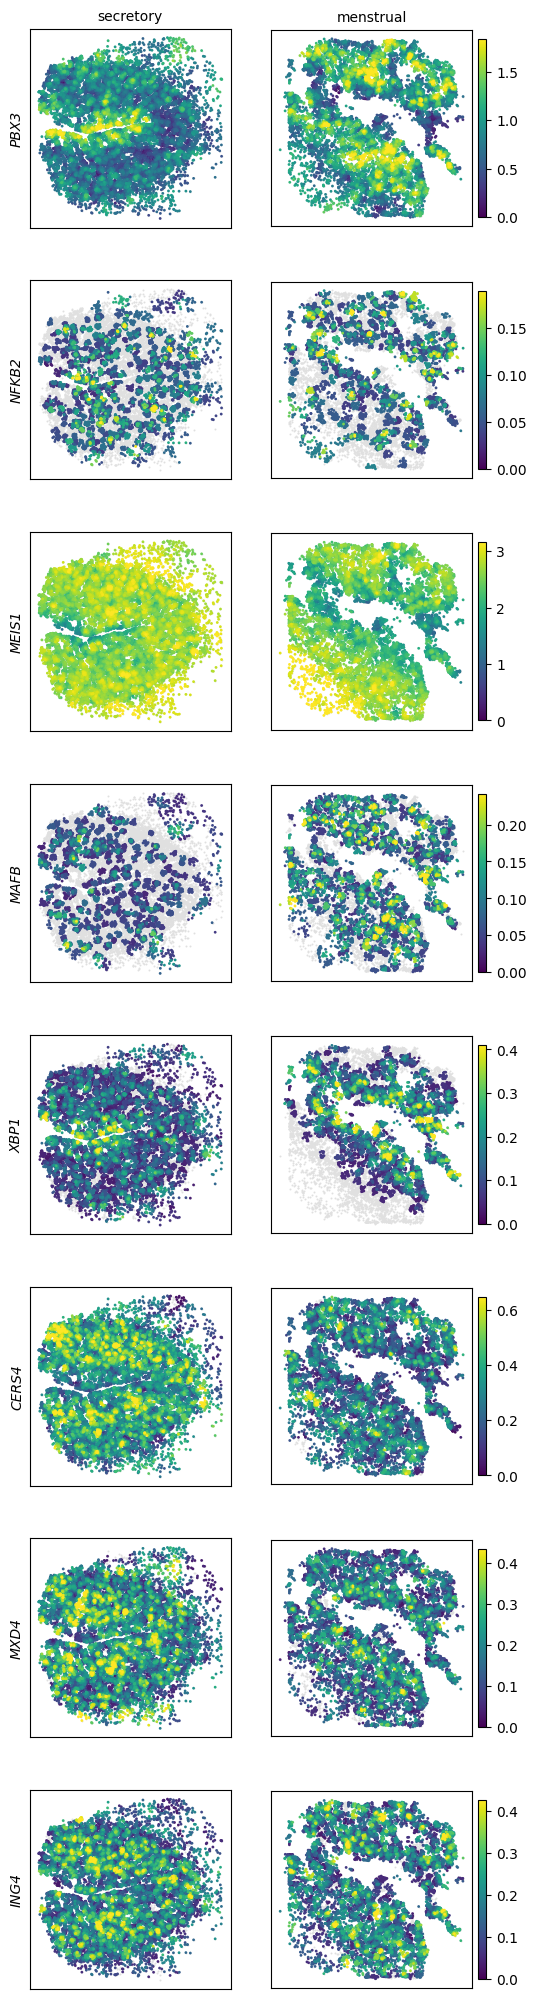

In [37]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import issparse

genes = ["PBX3", "NFKB2", "MEIS1", "MAFB", "XBP1", "CERS4", "MXD4", "ING4"]
smooth_k = 25        # 0 = raw per-cell; try 15-25 to average over spatial neighbours

layer = 'log1p' if 'log1p' in adata.layers else None
genes = [g for g in genes if g in adata.var_names]

obs = adata.obs
xy = obs[['x_um_dbscan', 'y_um_dbscan']]
mapped = xy.notna().all(axis=1)
tps = obs['timepoint'].astype(str)
levels = list(pd.unique(tps[mapped]))

sub = adata[:, genes]
X = sub.layers[layer] if layer else sub.X
E = pd.DataFrame(X.toarray() if issparse(X) else np.asarray(X),
                 index=adata.obs_names, columns=genes)
P = E.copy()

if smooth_k:
    from sklearn.neighbors import NearestNeighbors
    for tp in levels:                      # neighbours never cross a coordinate system
        m = (mapped & (tps == tp)).to_numpy()
        pos = xy[m].to_numpy()
        _, ind = NearestNeighbors(n_neighbors=min(smooth_k, m.sum())).fit(pos).kneighbors(pos)
        P.loc[m, genes] = E.loc[m, genes].to_numpy()[ind].mean(axis=1)

print(f"{mapped.sum():,} of {adata.n_obs:,} cells mapped")
print((E.loc[mapped] > 0).groupby(tps[mapped]).mean().round(3).T)   # frac-positive

fig, axes = plt.subplots(len(genes), len(levels),
                         figsize=(3.4 * len(levels), 3.2 * len(genes)), squeeze=False)
for i, g in enumerate(genes):
    vals = P.loc[mapped, g]
    vmax = np.percentile(vals[vals > 0], 99) if (vals > 0).any() else 1.0
    for j, tp in enumerate(levels):
        ax = axes[i, j]
        m = mapped & (tps == tp)
        x, y, v = (xy.loc[m, 'x_um_dbscan'].to_numpy(),
                   xy.loc[m, 'y_um_dbscan'].to_numpy(),
                   P.loc[m, g].to_numpy())
        ax.scatter(x, y, s=2, c='0.88', linewidths=0, rasterized=True)
        o = np.argsort(v)[np.sort(v) > 0]          # detected cells only, high drawn last
        pts = ax.scatter(x[o], y[o], c=v[o], s=4, cmap='viridis',
                         vmin=0, vmax=vmax, linewidths=0, rasterized=True)
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(tp, fontsize=10)
        if j == 0:
            ax.set_ylabel(g, style='italic', fontsize=10)
    fig.colorbar(pts, ax=axes[i, :].tolist(), shrink=0.85, pad=0.01)

fig.savefig('ds_markers_spatial.png', dpi=200, bbox_inches='tight')

presence-drivers: 18  |  absence-drivers: 18
presence: ['MMP11', 'DIO2', 'VCAN', 'LUM', 'SFRP4', 'COL3A1', 'RORB', 'IGFBP3', 'RBP1', 'ADAMTS9', 'PAMR1', 'GJA1', 'APCDD1', 'ADAM12', 'PGR', 'FBLN1', 'DCN', 'MDK']
absence : ['C11orf96', 'HSPA1A', 'HSPA1B', 'JUNB', 'IGFBP5', 'MT2A', 'FOS', 'EGR1', 'DNAJB1', 'GEM', 'ZFP36', 'NR4A1', 'ATF3', 'HSPH1', 'HSPB1', 'JUN', 'NFKBIA', 'NAMPT']


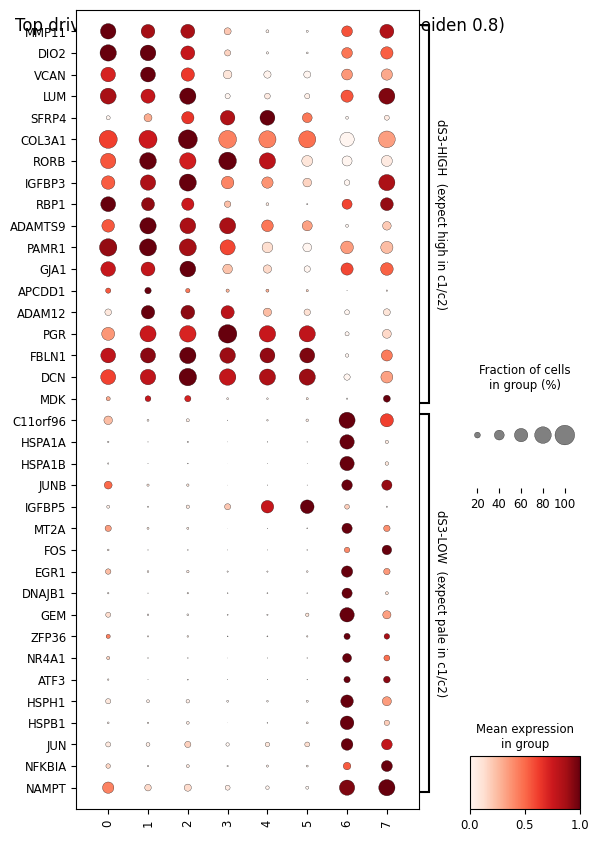

In [38]:
# Split the drivers by the SIGN of the atlas-centred value. Presence-drivers should be HIGH in
# c1/c2; absence-drivers should be PALE there. Plotting them together hides both patterns,
# because ~40% of this cosine is built from shared absence.
TOP = 18
pres = Ac[SUBT][Ac[SUBT] > 0]
absn = Ac[SUBT][Ac[SUBT] < 0]

drv = (contrib["1"] + contrib["2"]) / 2          # rank by mean contribution to the two clusters
g_pres = [g for g in drv.loc[drv.index.isin(pres.index)].nlargest(TOP).index
          if g in adata.var_names]
g_absn = [g for g in drv.loc[drv.index.isin(absn.index)].nlargest(TOP).index
          if g in adata.var_names]

panels_drv = {
    f"dS3-HIGH  (expect high in c1/c2)": g_pres,
    f"dS3-LOW  (expect pale in c1/c2)":  g_absn,
}
print(f"presence-drivers: {len(g_pres)}  |  absence-drivers: {len(g_absn)}")
print("presence:", g_pres)
print("absence :", g_absn)

sc.pl.dotplot(adata, panels_drv, groupby="leiden_0.8", layer=LAYER,
              standard_scale="var", swap_axes=True, cmap="Reds", figsize=(6.5, 10),
              title="Top drivers of the dS3 cosine, split by direction (leiden 0.8)",
              save="_dS3_drivers_split_leiden08.png")

leiden_1.2: 11 clusters | measured ceiling 0.1434

  Stro-5  -> c2  +0.1257  margin +0.0555 over c5   [BELOW ceiling]
  Stro-7  -> c9  +0.2583  margin +0.0645 over c10   [above]
  Stro-8  -> c4  +0.1585  margin +0.0019 over c0   [above]
  Stro-9  -> c3  +0.1272  margin +0.0149 over c1   [BELOW ceiling]
  Stro-10 -> c2  +0.2823  margin +0.0295 over c1   [above]
  Stro-11 -> c2  +0.1812  margin +0.0735 over c1   [above]
  Stro-1  -> c9  +0.1046  margin +0.0004 over c7   [IMPOSSIBLE]
  Stro-2  -> c9  +0.1434  margin +0.0339 over c6   [IMPOSSIBLE]
  Stro-3  -> c7  +0.0952  margin +0.0070 over c9   [IMPOSSIBLE]
  Stro-4  -> c4  +0.1021  margin +0.0216 over c7   [IMPOSSIBLE]
  Stro-6  -> c9  +0.1342  margin +0.0064 over c6   [IMPOSSIBLE]

each cluster's own best subtype (reciprocity):
  c0  n= 7,943 -> Stro-8  +0.1566 (next Stro-11 +0.0761)
  c1  n= 8,065 -> Stro-10 +0.2528 (next Stro-9 +0.1123)
  c2  n=   879 -> Stro-10 +0.2823 (next Stro-11 +0.1812)
  c3  n= 4,332 -> Stro-10 +0.2411 (next 

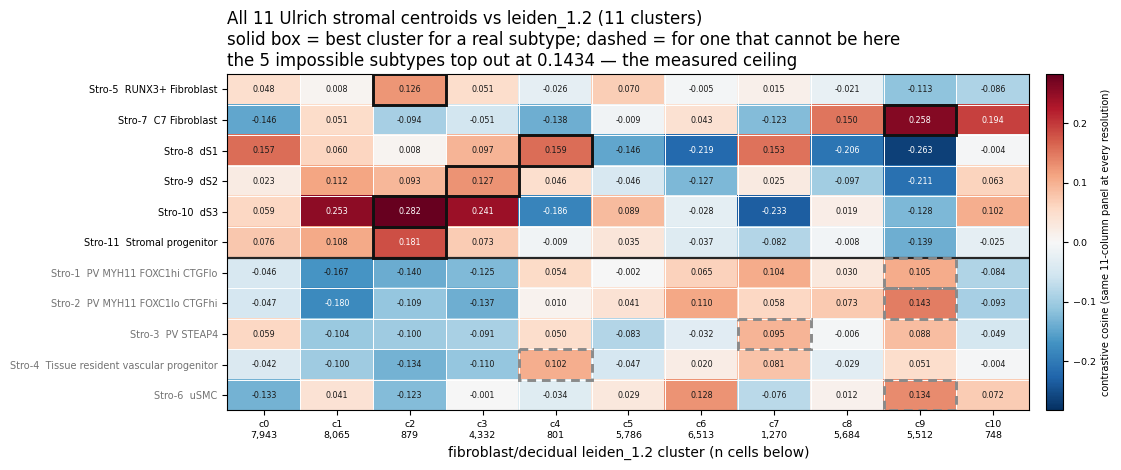

In [39]:
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from pathlib import Path

RESKEY = "leiden_1.2"          # or "leiden_0.8" / "leiden_1.0" / "leiden_0.5"
FR = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud/fib_fine_resolution_cosine")

K  = pd.read_csv(FR / f"cosine_11stromal_{RESKEY}.csv", index_col=0)
sz = pd.read_csv(FR / f"cluster_sizes_{RESKEY}.csv", index_col=0)["n_cells"]
K.index = K.index.astype(str); sz.index = sz.index.astype(str)
K = K.loc[sorted(K.index, key=int)]

NUM  = lambda s: int(str(s).split("_")[0].replace("Stro-", ""))
CTRL = {1, 2, 3, 4, 6}         # perivascular / vascular progenitor / uSMC: cannot be in a fib/dec object
M    = K.T
M    = M.loc[sorted(M.index, key=NUM)]
FIB  = [i for i in M.index if NUM(i) not in CTRL]
CON  = [i for i in M.index if NUM(i) in CTRL]
M    = M.loc[FIB + CON]
rows = list(M.index)

# the ceiling is MEASURED, not chosen: the best any impossible subtype achieves
ceil_ = float(M.loc[CON].max().max())
V     = float(np.abs(M.values).max())

fig, ax = plt.subplots(figsize=(0.72 * len(M.columns) + 3.4, 4.8))
im = ax.imshow(M.values, cmap="RdBu_r", aspect="auto",
               norm=mpl.colors.TwoSlopeNorm(vcenter=0.0, vmin=-V, vmax=V))
for i, r in enumerate(rows):
    for j in range(len(M.columns)):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=5.8,
                color="white" if abs(v) > 0.60 * V else "#1a1a1a")
    j = list(M.columns).index(M.loc[r].idxmax())
    ax.add_patch(mpl.patches.Rectangle(
        (j - .5, i - .5), 1, 1, fill=False, lw=2.1,
        edgecolor="#111111" if r in FIB else "#8a8a8a",
        linestyle="-" if r in FIB else (0, (3, 2)), zorder=5))

ax.axhline(len(FIB) - .5, color="0.15", lw=1.6)
ax.set_xticks(range(len(M.columns)))
ax.set_xticklabels([f"c{c}\n{sz[c]:,}" for c in M.columns], fontsize=6.8, linespacing=1.3)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"Stro-{NUM(r)}  {str(r).split('_', 1)[-1]}" for r in rows], fontsize=7)
for tick, r in zip(ax.get_yticklabels(), rows):
    if r in CON: tick.set_color("0.45")
ax.set_xlabel(f"fibroblast/decidual {RESKEY} cluster (n cells below)")
ax.set_title(f"All 11 Ulrich stromal centroids vs {RESKEY} ({len(M.columns)} clusters)\n"
             f"solid box = best cluster for a real subtype; dashed = for one that cannot be here\n"
             f"the 5 impossible subtypes top out at {ceil_:.4f} — the measured ceiling", loc="left")
cb = fig.colorbar(im, ax=ax, fraction=.030, pad=.02)
cb.set_label("contrastive cosine (same 11-column panel at every resolution)", fontsize=7)
cb.ax.tick_params(labelsize=6.8)
ax.set_xticks(np.arange(-.5, len(M.columns), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(rows), 1), minor=True)
ax.grid(which="minor", color="white", lw=.7); ax.tick_params(which="minor", length=0)
fig.tight_layout()
fig.savefig(f"cosine_heatmap_{RESKEY}.png", dpi=300, bbox_inches="tight")

# who wins what, and does each cluster pick its subtype back?
print(f"{RESKEY}: {len(M.columns)} clusters | measured ceiling {ceil_:.4f}\n")
for r in rows:
    s = M.loc[r].sort_values(ascending=False)
    tag = "IMPOSSIBLE" if r in CON else ("above" if s.iloc[0] > ceil_ else "BELOW ceiling")
    print(f"  Stro-{NUM(r):<2d} -> c{s.index[0]:<2s} {s.iloc[0]:+.4f}  "
          f"margin {s.iloc[0]-s.iloc[1]:+.4f} over c{s.index[1]}   [{tag}]")
print("\neach cluster's own best subtype (reciprocity):")
for cl_ in K.index:
    s = K.loc[cl_].sort_values(ascending=False)
    print(f"  c{cl_:<2s} n={sz[cl_]:>6,} -> Stro-{NUM(s.index[0]):<2d} {s.iloc[0]:+.4f} "
          f"(next Stro-{NUM(s.index[1])} {s.iloc[1]:+.4f})")

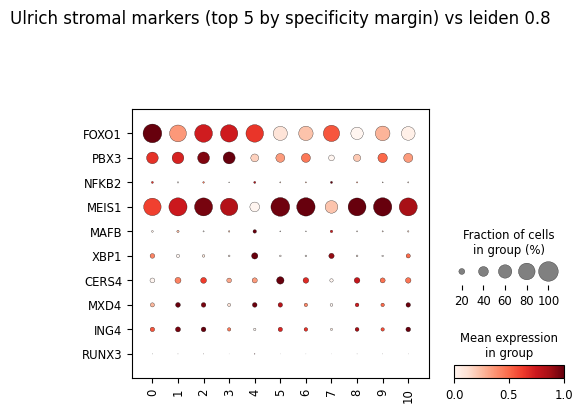

In [41]:
sc.pl.dotplot(
    adata, ["FOXO1","PBX3", "NFKB2", "MEIS1", "MAFB", "XBP1", "CERS4", "MXD4", "ING4", "RUNX3"], groupby="leiden_1.2", layer=LAYER,
    standard_scale="var",          # scale each GENE 0-1 across clusters, so specificity is visible
    swap_axes=True, dendrogram=False, cmap="Reds",
  #  figsize=(7, 13),
    title="Ulrich stromal markers (top 5 by specificity margin) vs leiden 0.8",
    save="_stromal_markers_leiden08.png",
)

In [42]:
allcells = sc.read_h5ad("/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_Human_All_Cells.h5ad")

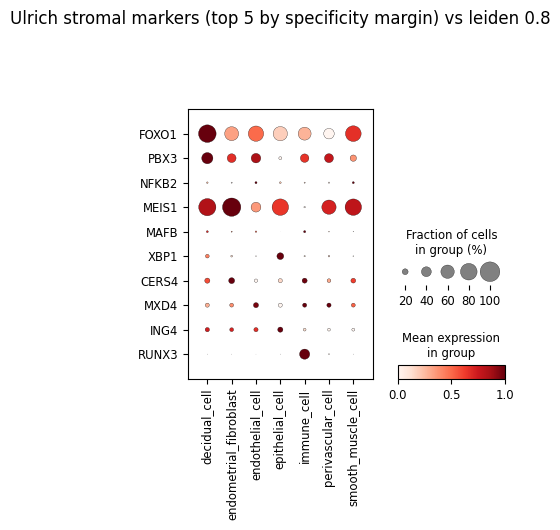

In [59]:
sc.pl.dotplot(
    allcells, ["FOXO1","PBX3", "NFKB2", "MEIS1", "MAFB", "XBP1", "CERS4", "MXD4", "ING4", "RUNX3"], groupby="cell_type", layer=LAYER,
    standard_scale="var",          # scale each GENE 0-1 across clusters, so specificity is visible
    swap_axes=True, dendrogram=False, cmap="Reds",
  #  figsize=(7, 13),
    title="Ulrich stromal markers (top 5 by specificity margin) vs leiden 0.8",
    save="_stromal_markers_leiden08.png",
)

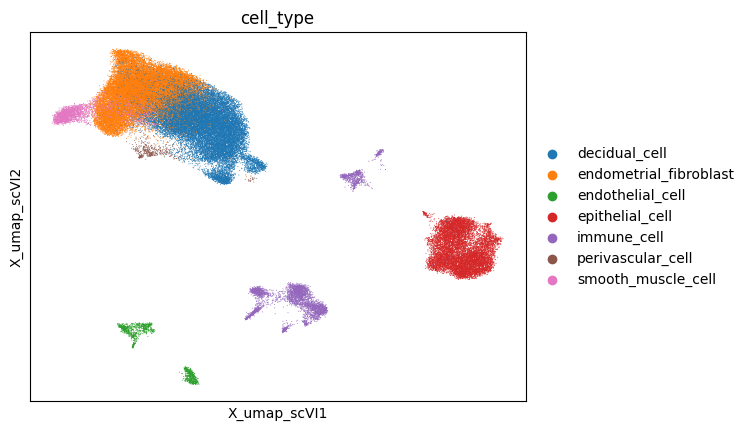

In [60]:
sc.pl.embedding(allcells, basis = 'X_umap_scVI', color = 'cell_type')

In [62]:
REG = Path("/n/lab_storage/eddy_lab/Lab/mckinley_backup_2025-12-18/data/"
           "2026_06_24_human_regulons.h5ad")
r = sc.read_h5ad(REG)

In [64]:
r.X

array([[0.03800234, 0.06581195, 0.04563262, ..., 0.04239411, 0.02283065,
        0.06406578],
       [0.03288976, 0.08725026, 0.04757865, ..., 0.09584479, 0.03761321,
        0.07732941],
       [0.02155917, 0.02082436, 0.03275258, ..., 0.07598291, 0.03010725,
        0.05092096],
       ...,
       [0.03071839, 0.01340195, 0.02694914, ..., 0.06057058, 0.03186947,
        0.02707691],
       [0.02557829, 0.04709944, 0.02643195, ..., 0.10752026, 0.04430319,
        0.0311995 ],
       [0.0180753 , 0.04625978, 0.02356183, ..., 0.0641911 , 0.03557552,
        0.04498681]], shape=(44756, 132), dtype=float32)

In [69]:
R = r

In [72]:
import anndata as ad, numpy as np, pandas as pd, scipy.sparse as sp
from pathlib import Path

REG = Path("/n/lab_storage/eddy_lab/Lab/mckinley_backup_2025-12-18/data/"
           "2026_06_24_human_regulons.h5ad")
rg = ad.read_h5ad(REG)
rg.obs_names = rg.obs_names.astype(str)

Xs = rg.X[:1000]; Xs = Xs.toarray() if sp.issparse(Xs) else np.asarray(Xs)
assert Xs.min() >= 0 and Xs.max() <= 1.0001, "X not in [0,1] — not an AUCell matrix"

# Barcode conventions have differed between objects in this project, so try candidate forms
# and pick the best rather than assuming. A silent partial join would bias every cluster mean.
target = set(lab.index)
cands = {"as-is": pd.Index(rg.obs_names),
         "join normalised": pd.Index(rg.obs_names).str.replace(r"[-_]1[-_]", "-1-", regex=True)}
for col in rg.obs.columns:
    v = rg.obs[col].astype(str)
    if v.str.contains("mck", case=False).any() and v.nunique() < 20:
        cands[f"16mer + obs['{col}']"] = pd.Index(
            pd.Index(rg.obs_names).str.extract(r"([ACGT]{16})", expand=False).fillna("") +
            "-1-" + v.values)
name, ix = max(((k, v) for k, v in cands.items()),
               key=lambda kv: len(target & set(kv[1])))
n = len(target & set(ix))
for k, v in cands.items():
    print(f"  {k:26s} {len(target & set(v)):>6,} / {len(target):,}")
print(f"\nusing '{name}': {n:,} matched ({n/len(target):.1%})")
assert n > 0.5 * len(target), f"barcode conventions do not reconcile; sample: {list(rg.obs_names[:3])}"
rg.obs_names = ix

RES = [c for c in lab.columns if c.startswith("leiden_")]

# duplicate barcodes would silently double-count cells in every cluster mean
dup = pd.Index(rg.obs_names).duplicated().sum()
print(f"duplicate barcodes after the 16mer+sample rebuild: {dup:,}")
assert dup == 0, "duplicated barcodes — the 16mer extract collided; inspect rg.obs_names"

lab_al = lab.reindex(rg.obs_names)              # NaN preserved for unmatched cells
mask   = lab_al[RES[0]].notna().values
R      = rg[mask].copy()
for c in RES:
    v = lab_al.loc[R.obs_names, c].astype(str)
    R.obs[c] = pd.Categorical(v, categories=sorted(v.unique(), key=int), ordered=True)

print(f"R: {R.n_obs:,} cells x {R.n_vars} regulons  (dropped {rg.n_obs - R.n_obs:,} unmatched)")
for c in RES:
    print(f"  {c}: {R.obs[c].nunique()} clusters, "
          f"sizes {R.obs[c].value_counts().sort_index().to_dict()}")

# Is the 7% dropout random, or concentrated in particular clusters? A cluster that lost most of
# its cells will have a noisy mean AUC, and one that lost them non-randomly will have a biased one.
have = pd.Series(R.obs_names).isin(lab.index)
cov = pd.DataFrame({
    "in_lab":    lab["leiden_0.8"].value_counts(),
    "in_regulon": pd.Series(R.obs["leiden_0.8"]).value_counts(),
}).fillna(0).astype(int)
cov["pct_recovered"] = (100 * cov.in_regulon / cov.in_lab).round(1)
print("\nper-cluster recovery in the regulon object (leiden_0.8):")
print(cov.sort_index(key=lambda s: s.astype(int)).to_string())

  as-is                           0 / 47,533
  join normalised                 0 / 47,533
  16mer + obs['sample']      44,200 / 47,533

using '16mer + obs['sample']': 44,200 matched (93.0%)
duplicate barcodes after the 16mer+sample rebuild: 0
R: 44,200 cells x 132 regulons  (dropped 556 unmatched)
  leiden_0.5: 6 clusters, sizes {'0': 8787, '1': 10303, '2': 18974, '3': 4348, '4': 761, '5': 1027}
  leiden_0.8: 8 clusters, sizes {'0': 7662, '1': 3864, '2': 9294, '3': 4800, '4': 11263, '5': 5394, '6': 1207, '7': 716}
  leiden_1.0: 10 clusters, sizes {'0': 7376, '1': 8360, '2': 3875, '3': 714, '4': 7172, '5': 1205, '6': 5713, '7': 3825, '8': 5215, '9': 745}
  leiden_1.2: 11 clusters, sizes {'0': 7413, '1': 7544, '2': 833, '3': 3949, '4': 764, '5': 5502, '6': 5867, '7': 1236, '8': 5363, '9': 5067, '10': 662}

per-cluster recovery in the regulon object (leiden_0.8):
            in_lab  in_regulon  pct_recovered
leiden_0.8                                   
0             8220        7662     


=== leiden_0.8: raw mean AUC, paper TFs (not z-scored) ===
   HOXA10   NR2F2   FOXO1  HOXA13   HOXA3  HOXD10   MEIS1    MAFB    XBP1    MXD4   STAT1   STAT2    PBX1   NFKB1
0  0.0331  0.0718  0.1156  0.0491  0.0284  0.0350  0.0766  0.0526  0.0498  0.0563  0.0479  0.0377  0.0648  0.0775
1  0.0409  0.0833  0.1015  0.0721  0.0385  0.0407  0.0840  0.0418  0.0446  0.0575  0.0460  0.0348  0.0842  0.0571
2  0.0463  0.1010  0.0943  0.0742  0.0423  0.0371  0.0847  0.0424  0.0524  0.0551  0.0448  0.0365  0.0966  0.0551
3  0.0425  0.0629  0.0831  0.0602  0.0594  0.0346  0.0993  0.0299  0.0252  0.0545  0.0382  0.0293  0.1363  0.0541
4  0.0462  0.0694  0.0750  0.0652  0.0534  0.0301  0.0918  0.0342  0.0332  0.0517  0.0373  0.0312  0.1370  0.0531
5  0.0422  0.0722  0.0768  0.0630  0.0488  0.0314  0.0883  0.0407  0.0336  0.0546  0.0364  0.0306  0.1366  0.0568
6  0.0328  0.0600  0.1060  0.0494  0.0240  0.0247  0.0612  0.0872  0.0621  0.0751  0.0329  0.0313  0.0527  0.1397
7  0.0283  0.0632  0.1174  0

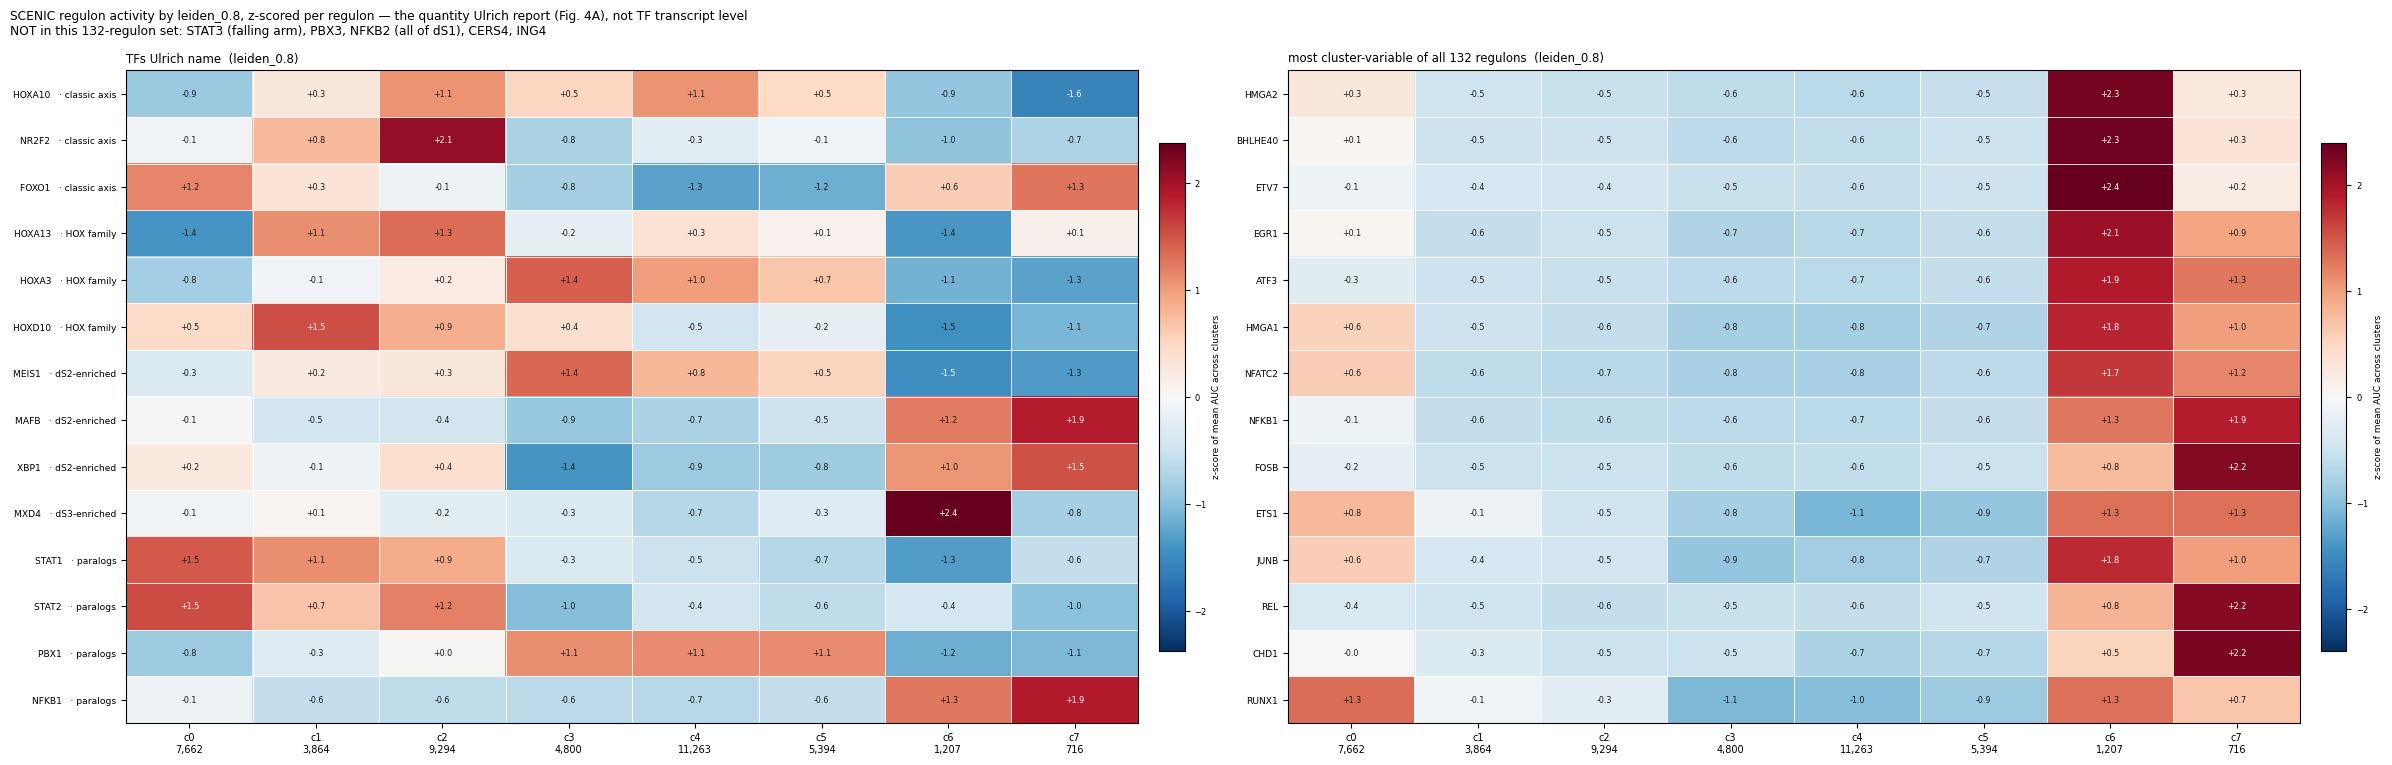

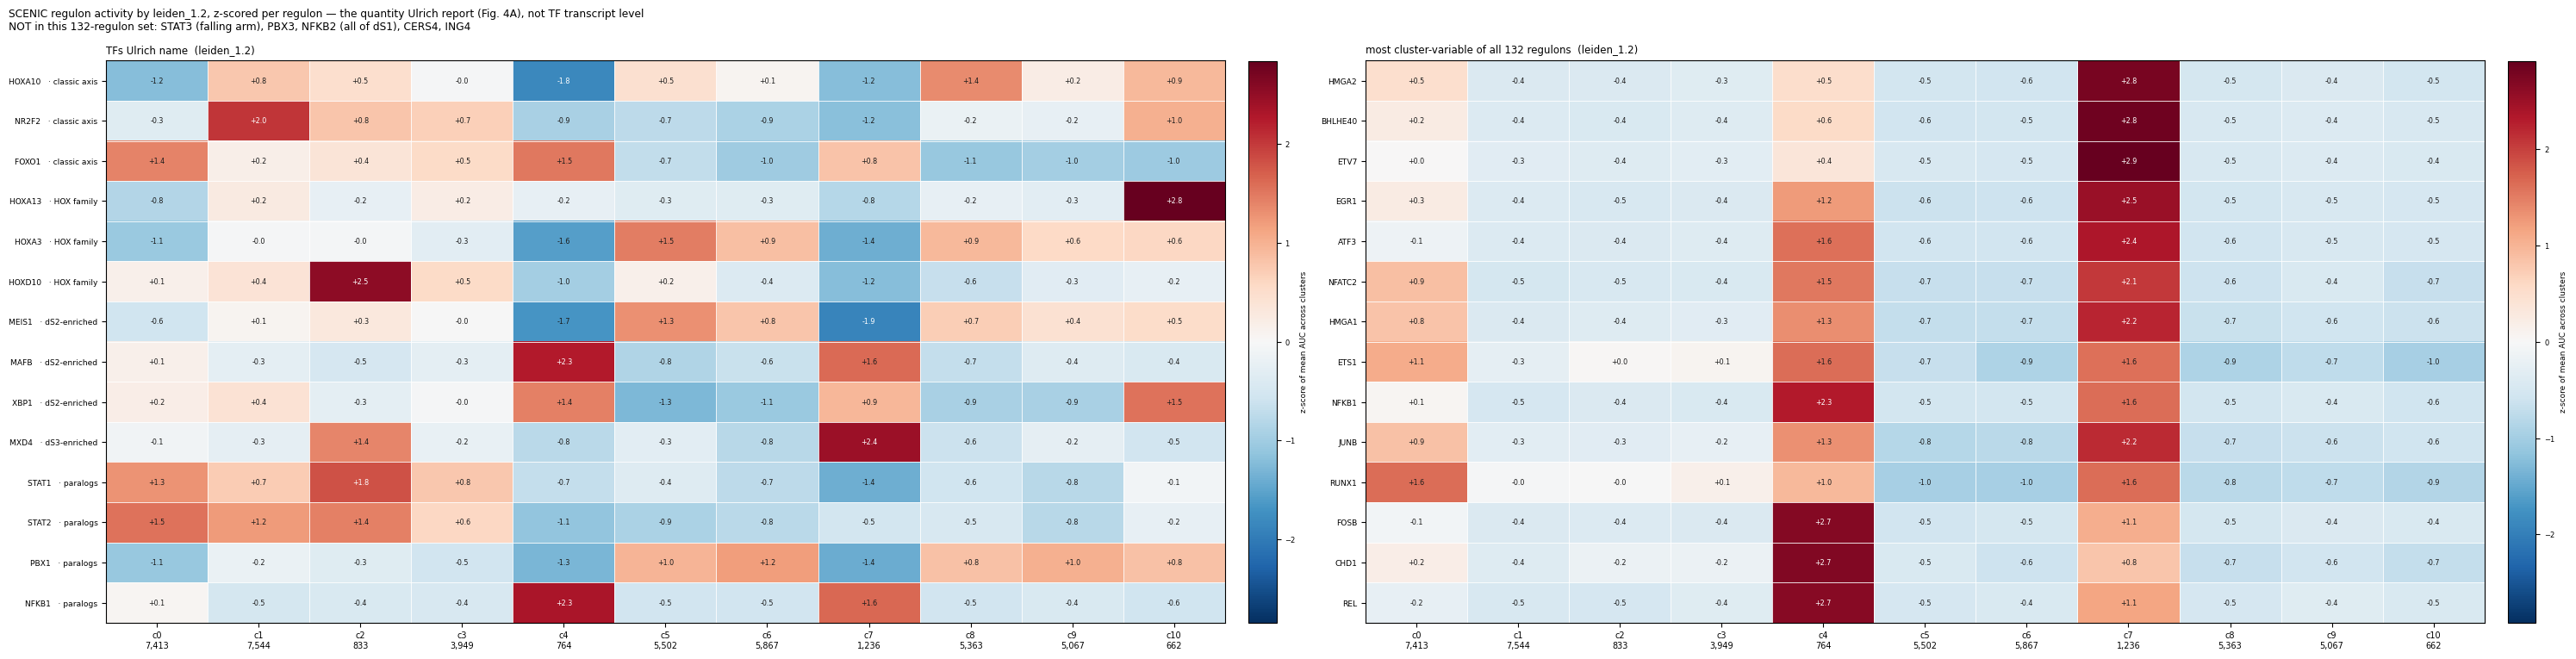

In [73]:
import matplotlib as mpl, matplotlib.pyplot as plt

# Grouped so the readable claim is visible. Paralogs of the ABSENT TFs are shown separately and
# labelled as such — STAT1/STAT2 are not stand-ins for STAT3, and PBX1/NFKB1 are not PBX3/NFKB2.
BLOCKS = [
    ("classic axis — rises toward dS3", ["HOXA10", "NR2F2"]),
    ("classic axis — high in all three", ["FOXO1"]),
    ("HOX family (context)",            ["HOXA13", "HOXA3", "HOXD10"]),
    ("dS2-enriched (complete)",         ["MEIS1", "MAFB", "XBP1"]),
    ("dS3-enriched (1 of 3)",           ["MXD4"]),
    ("paralogs — NOT substitutes",      ["STAT1", "STAT2", "PBX1", "NFKB1"]),
]
MISSING = "STAT3 (falling arm), PBX3, NFKB2 (all of dS1), CERS4, ING4"

def regulon_heatmap(group, top_n=14):
    cl    = R.obs[group].astype(str)
    order = sorted(cl.unique(), key=int)
    sizes = cl.value_counts()

    dense = R.X.toarray() if sp.issparse(R.X) else np.asarray(R.X)
    A     = pd.DataFrame(dense, index=R.obs_names,
                         columns=pd.Index(R.var_names).str.replace(r"\(\+\)|\(-\)", "", regex=True))
    mean  = A.groupby(cl.values).mean().loc[order]           # cluster x regulon

    rows  = [(g, lbl) for lbl, gs in BLOCKS for g in gs if g in mean.columns]
    names = [g for g, _ in rows]
    top   = mean.std(axis=0).nlargest(top_n).index.tolist()

    fig, axs = plt.subplots(1, 2, figsize=(2.0*len(order) + 8.0, 0.34*max(len(names), top_n) + 3.0))
    for ax, (cols, ttl, ylab) in zip(axs, [
            (names, f"TFs Ulrich name  ({group})", [f"{g}   · {l.split(' —')[0].split(' (')[0]}"
                                                    for g, l in rows]),
            (top,   f"most cluster-variable of all {R.n_vars} regulons  ({group})", top)]):
        M = mean[cols]
        # z-score PER REGULON: AUCell scales with regulon size, so an unscaled heatmap ranks
        # regulons by target-gene count and hides the cluster pattern the paper's claim is about
        Z = ((M - M.mean(axis=0)) / M.std(axis=0).replace(0, np.nan)).T
        V = float(np.nanmax(np.abs(Z.values)))
        im = ax.imshow(Z.values, cmap="RdBu_r", aspect="auto",
                       norm=mpl.colors.TwoSlopeNorm(vcenter=0., vmin=-V, vmax=V))
        for i in range(Z.shape[0]):
            for j in range(Z.shape[1]):
                v = Z.values[i, j]
                if np.isfinite(v):
                    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=5.8,
                            color="white" if abs(v) > .62*V else "#1a1a1a")
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels([f"c{c}\n{sizes[c]:,}" for c in order], fontsize=7, linespacing=1.3)
        ax.set_yticks(range(Z.shape[0])); ax.set_yticklabels(ylab, fontsize=6.6)
        ax.set_title(ttl, fontsize=8.5, loc="left")
        ax.set_xticks(np.arange(-.5, len(order), 1), minor=True)
        ax.set_yticks(np.arange(-.5, Z.shape[0], 1), minor=True)
        ax.grid(which="minor", color="white", lw=.6); ax.tick_params(which="minor", length=0)
        cb = fig.colorbar(im, ax=ax, fraction=.024, pad=.02)
        cb.set_label("z-score of mean AUC across clusters", fontsize=6.5)
        cb.ax.tick_params(labelsize=6)
    fig.suptitle(f"SCENIC regulon activity by {group}, z-scored per regulon — the quantity Ulrich "
                 f"report (Fig. 4A), not TF transcript level\n"
                 f"NOT in this 132-regulon set: {MISSING}",
                 x=.005, ha="left", fontsize=8.8)
    fig.tight_layout()
    fig.savefig(f"regulon_heatmap_{group}.png", dpi=300, bbox_inches="tight")

    print(f"\n=== {group}: raw mean AUC, paper TFs (not z-scored) ===")
    print(mean[names].round(4).to_string())
    return mean

m08 = regulon_heatmap("leiden_0.8")
m12 = regulon_heatmap("leiden_1.2")

In [75]:
# Where do the paper's TFs rank among ALL 132 regulons for the dS3 clusters? A z of +2.1 means
# little on its own; being 2nd of 132 means a lot. This is the claim, stated as a rank.
DS3_08 = ["1", "2"]          # dS3's clusters at 0.8 (cosine 0.2998, 0.2940)

cl   = R.obs["leiden_0.8"].astype(str)
dense = R.X.toarray() if sp.issparse(R.X) else np.asarray(R.X)
A = pd.DataFrame(dense, index=R.obs_names,
                 columns=pd.Index(R.var_names).str.replace(r"\(\+\)|\(-\)", "", regex=True))
mean = A.groupby(cl.values).mean()
Z = (mean - mean.mean(axis=0)) / mean.std(axis=0).replace(0, np.nan)   # cluster x regulon

for c in DS3_08:
    order = Z.loc[c].sort_values(ascending=False)
    print(f"\n--- c{c}: top 10 of {len(order)} regulons by z ---")
    print(order.head(10).round(2).to_string())
    for tf in ["NR2F2", "HOXA10", "FOXO1", "MXD4", "MEIS1", "MAFB", "XBP1"]:
        if tf in order.index:
            print(f"    {tf:7s} rank {list(order.index).index(tf)+1:>3d}/{len(order)}  "
                  f"z={order[tf]:+.2f}")

# do the two dS3 clusters share a regulon state, or resemble dS3 for different reasons?
print(f"\nregulon-profile correlation between c1 and c2: "
      f"{Z.loc['1'].corr(Z.loc['2'], method='spearman'):.3f}")
print("(compare with the other cluster pairs)")
print(Z.T.corr(method='spearman').round(2).to_string())


--- c1: top 10 of 132 regulons by z ---
HOXD10     1.52
ETV1       1.45
LEF1       1.33
FOSL2      1.31
WT1        1.30
CHURC1     1.28
NFYB       1.23
IRF9       1.22
ZNF354C    1.20
ZNF75D     1.15
    NR2F2   rank  21/132  z=+0.77
    HOXA10  rank  44/132  z=+0.28
    FOXO1   rank  38/132  z=+0.32
    MXD4    rank  52/132  z=+0.07
    MEIS1   rank  49/132  z=+0.22
    MAFB    rank  95/132  z=-0.46
    XBP1    rank  62/132  z=-0.11

--- c2: top 10 of 132 regulons by z ---
NR2F2     2.08
NFE2L1    1.89
MAF       1.81
FOSL2     1.37
HOXA13    1.32
CEBPD     1.30
STAT2     1.20
HOXA10    1.07
NFYB      0.91
WT1       0.90
    NR2F2   rank   1/132  z=+2.08
    HOXA10  rank   8/132  z=+1.07
    FOXO1   rank  55/132  z=-0.11
    MXD4    rank  62/132  z=-0.24
    MEIS1   rank  32/132  z=+0.26
    MAFB    rank  77/132  z=-0.44
    XBP1    rank  23/132  z=+0.41

regulon-profile correlation between c1 and c2: 0.822
(compare with the other cluster pairs)
      0     1     2     3     4     5  

In [76]:
# The formal version of the rank claim, plus the c1-vs-c2 table for the rebuttal.
from scipy.stats import hypergeom

N = Z.shape[1]
for c in ["1", "2"]:
    o = Z.loc[c].sort_values(ascending=False)
    r_nr, r_hx = list(o.index).index("NR2F2") + 1, list(o.index).index("HOXA10") + 1
    print(f"c{c}: NR2F2 rank {r_nr}/{N} (p={r_nr/N:.4f} for a pre-named regulon), "
          f"HOXA10 rank {r_hx}/{N} (p={r_hx/N:.4f})")

# both ends of the axis, in one table
DS1_08, DS3_08 = ["7"], ["1", "2"]
ax = pd.DataFrame({
    "dS1_cluster_c7": Z.loc[DS1_08[0], ["HOXA10", "NR2F2", "FOXO1", "MXD4"]],
    "dS3_cluster_c1": Z.loc["1",       ["HOXA10", "NR2F2", "FOXO1", "MXD4"]],
    "dS3_cluster_c2": Z.loc["2",       ["HOXA10", "NR2F2", "FOXO1", "MXD4"]],
})
ax["rank_in_c2"] = [list(Z.loc["2"].sort_values(ascending=False).index).index(g) + 1
                    for g in ax.index]
ax["paper_predicts"] = ["rises to dS3", "rises to dS3", "high in all three", "dS3-enriched"]
print("\n" + ax.round(2).to_string())
ax.to_csv("ds3_regulon_axis_leiden08.csv")

c1: NR2F2 rank 21/132 (p=0.1591 for a pre-named regulon), HOXA10 rank 44/132 (p=0.3333)
c2: NR2F2 rank 1/132 (p=0.0076 for a pre-named regulon), HOXA10 rank 8/132 (p=0.0606)

        dS1_cluster_c7  dS3_cluster_c1  dS3_cluster_c2  rank_in_c2     paper_predicts
HOXA10           -1.59            0.28            1.07           8       rises to dS3
NR2F2            -0.73            0.77            2.08           1       rises to dS3
FOXO1             1.27            0.32           -0.11          55  high in all three
MXD4             -0.79            0.07           -0.24          62       dS3-enriched


not in adata.var_names: none

=== leiden_0.8: detection rate per cluster (% cells with >=1 count) ===
           0     1     2     3     4     5     6     7
STAT3   57.8  45.4  49.0  37.5  33.7  34.3  36.6  52.3
FOXO1   93.6  84.9  80.1  67.2  58.6  68.4  77.8  86.3
HOXA10  18.2  16.3  24.6  20.5  17.7  15.5  10.0  10.2
NR2F2   66.8  64.7  78.4  61.0  56.8  54.2  44.6  51.3
PBX3    49.6  51.7  48.9  37.0  30.6  36.8  19.0  28.4
NFKB2    4.6   1.7   2.8   1.9   2.3   2.0   5.1   4.8
MEIS1   85.0  86.4  89.8  94.3  90.0  91.5  55.1  36.9
MAFB     3.9   2.9   5.3   1.5   1.9   2.4   6.6  10.1
XBP1    14.5   4.0   8.9   3.2   4.4   3.6  17.3  21.7
CERS4   15.4  14.9  21.1  27.4  19.2  16.0   9.6  16.9
MXD4    12.5   9.1  15.4  12.9  10.5  10.1   7.4  14.2
ING4    13.7   9.7  16.5  12.8  11.2   9.7   5.1   5.6

=== leiden_1.2: detection rate per cluster (% cells with >=1 count) ===
           0     1     2     3     4     5     6     7     8     9    10
STAT3   57.9  50.1  51.2  45.0  51.8 

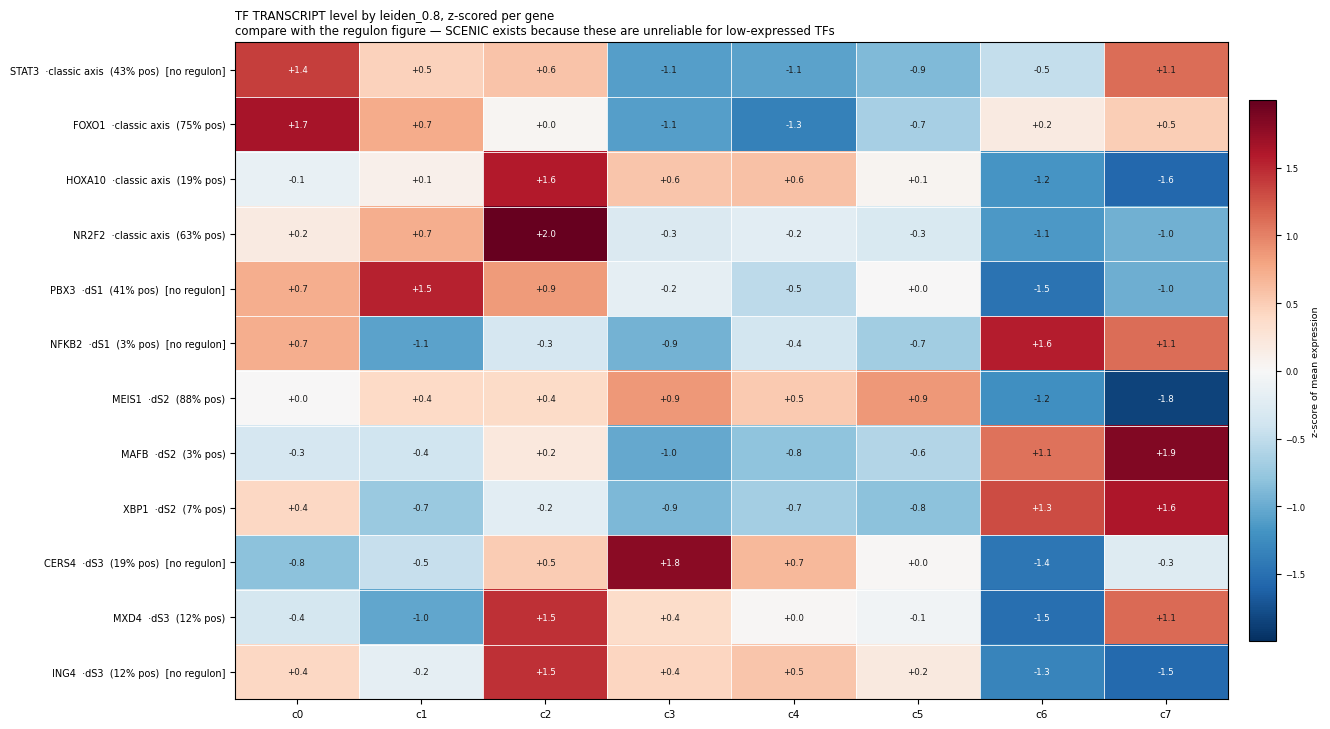

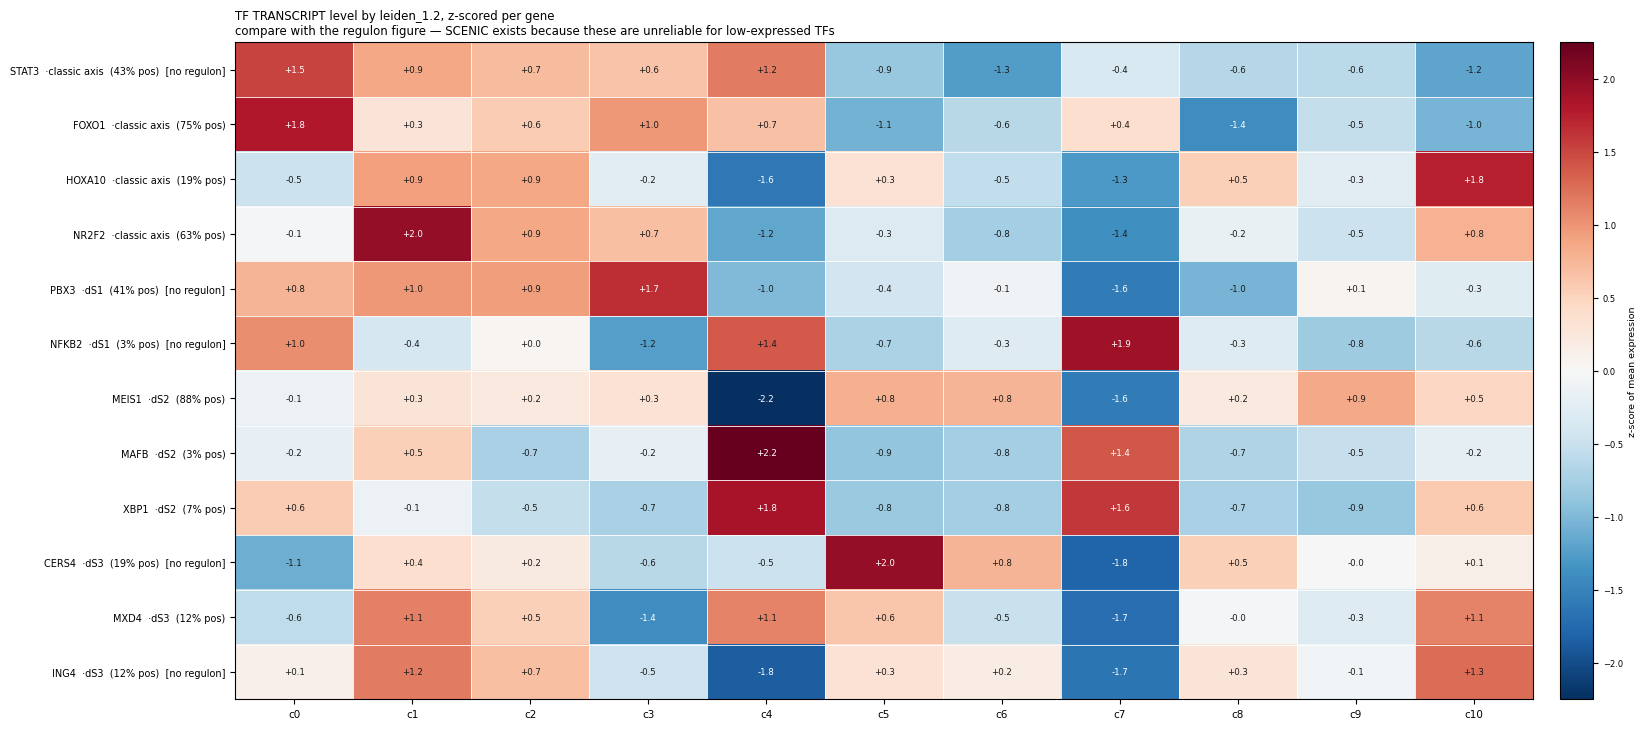

In [77]:
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib as mpl, matplotlib.pyplot as plt

# Same 12 TFs, same row grouping as the regulon figure, so the two are directly comparable.
BLOCKS = [("classic axis", ["STAT3", "FOXO1", "HOXA10", "NR2F2"]),
          ("dS1-enriched", ["PBX3", "NFKB2"]),
          ("dS2-enriched", ["MEIS1", "MAFB", "XBP1"]),
          ("dS3-enriched", ["CERS4", "MXD4", "ING4"])]
TFS  = [g for _, gs in BLOCKS for g in gs]
GRPOF = {g: b for b, gs in BLOCKS for g in gs}
have  = [g for g in TFS if g in adata.var_names]
print("not in adata.var_names:", [g for g in TFS if g not in adata.var_names] or "none")

Xl = adata.layers[LAYER] if LAYER else adata.X
sub = adata[:, have]
Xs  = sub.layers[LAYER] if LAYER else sub.X
Xs  = Xs.toarray() if sp.issparse(Xs) else np.asarray(Xs)
E   = pd.DataFrame(Xs, index=adata.obs_names, columns=have)

def tf_gene_heatmap(group):
    cl    = adata.obs[group].astype(str)
    order = sorted(cl.unique(), key=int)
    mean  = E.groupby(cl.values).mean().loc[order]
    pct   = (100 * (E > 0).groupby(cl.values).mean()).loc[order]

    # z-score per GENE across clusters, same as the regulon figure
    Zg = ((mean - mean.mean(axis=0)) / mean.std(axis=0).replace(0, np.nan)).T
    V  = float(np.nanmax(np.abs(Zg.values)))

    fig, ax = plt.subplots(figsize=(1.05*len(order) + 5.0, 0.40*len(have) + 2.6))
    im = ax.imshow(Zg.values, cmap="RdBu_r", aspect="auto",
                   norm=mpl.colors.TwoSlopeNorm(vcenter=0., vmin=-V, vmax=V))
    for i in range(Zg.shape[0]):
        for j in range(Zg.shape[1]):
            v = Zg.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6.2,
                        color="white" if abs(v) > .62*V else "#1a1a1a")
    ax.set_xticks(range(len(order))); ax.set_xticklabels([f"c{c}" for c in order], fontsize=7.5)
    # annotate each row with detection rate and whether a regulon exists for it
    REG_HAVE = {"FOXO1", "HOXA10", "NR2F2", "MEIS1", "MAFB", "XBP1", "MXD4"}
    ylab = [f"{g}  ·{GRPOF[g].split('-')[0]}  ({(E[g] > 0).mean()*100:.0f}% pos)"
            f"{'' if g in REG_HAVE else '  [no regulon]'}" for g in Zg.index]
    ax.set_yticks(range(len(ylab))); ax.set_yticklabels(ylab, fontsize=7)
    ax.set_title(f"TF TRANSCRIPT level by {group}, z-scored per gene\n"
                 "compare with the regulon figure — SCENIC exists because these are unreliable "
                 "for low-expressed TFs", fontsize=8.5, loc="left")
    ax.set_xticks(np.arange(-.5, len(order), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(ylab), 1), minor=True)
    ax.grid(which="minor", color="white", lw=.6); ax.tick_params(which="minor", length=0)
    cb = fig.colorbar(im, ax=ax, fraction=.026, pad=.02)
    cb.set_label("z-score of mean expression", fontsize=6.8); cb.ax.tick_params(labelsize=6)
    fig.tight_layout(); fig.savefig(f"tf_transcript_heatmap_{group}.png", dpi=300,
                                    bbox_inches="tight")

    print(f"\n=== {group}: detection rate per cluster (% cells with >=1 count) ===")
    print(pct.round(1).T.to_string())
    return mean, pct, Zg

m08g, p08g, Z08g = tf_gene_heatmap("leiden_0.8")
m12g, p12g, Z12g = tf_gene_heatmap("leiden_1.2")

In [78]:
# The two things this view can answer that the regulons cannot.

# 1. STAT3's falling arm. Paper: high in dS1/dS2, LOW in dS3. c7 = dS1 cluster, c2 = dS3.
print("STAT3 transcript, z by cluster (leiden_0.8):")
print(Z08g.loc["STAT3"].round(2).to_string())
s = Z08g.loc["STAT3"]
print(f"\n  dS1 cluster c7: {s['7']:+.2f}   dS3 cluster c2: {s['2']:+.2f}   "
      f"difference {s['7']-s['2']:+.2f}")
print(f"  paper predicts c7 > c2 -> {'CONSISTENT' if s['7'] > s['2'] else 'NOT CONSISTENT'}")
print(f"  STAT3 detection: {(E['STAT3'] > 0).mean()*100:.1f}% of cells")

# 2. Do transcript and regulon agree, per TF, across clusters? This is the methodological point.
REG_HAVE = ["FOXO1", "HOXA10", "NR2F2", "MEIS1", "MAFB", "XBP1", "MXD4"]
rows = []
for g in REG_HAVE:
    if g in Z08g.index and g in Z.columns:
        a = Z08g.loc[g].astype(float)
        b = Z[g].reindex(a.index).astype(float)          # Z from the regulon cell (cluster x regulon)
        rows.append(dict(TF=g, pct_cells_pos=round((E[g] > 0).mean()*100, 1),
                         spearman_transcript_vs_regulon=round(a.corr(b, method="spearman"), 3),
                         top_cluster_transcript=f"c{a.idxmax()}",
                         top_cluster_regulon=f"c{b.idxmax()}",
                         agree=bool(a.idxmax() == b.idxmax())))
AG = pd.DataFrame(rows).sort_values("pct_cells_pos")
print("\n=== transcript vs regulon agreement (leiden_0.8) ===")
print(AG.to_string(index=False))
print(f"\nsame top cluster: {int(AG.agree.sum())}/{len(AG)}")

STAT3 transcript, z by cluster (leiden_0.8):
0    1.37
1    0.46
2    0.58
3   -1.09
4   -1.07
5   -0.88
6   -0.48
7    1.11

  dS1 cluster c7: +1.11   dS3 cluster c2: +0.58   difference +0.53
  paper predicts c7 > c2 -> CONSISTENT
  STAT3 detection: 43.0% of cells

=== transcript vs regulon agreement (leiden_0.8) ===
    TF  pct_cells_pos  spearman_transcript_vs_regulon top_cluster_transcript top_cluster_regulon  agree
  MAFB            3.3                           0.976                     c7                  c7   True
  XBP1            7.4                           0.905                     c7                  c7   True
  MXD4           11.9                          -0.738                     c2                  c6  False
HOXA10           18.8                           0.976                     c2                  c2   True
 NR2F2           63.5                           0.810                     c2                  c2   True
 FOXO1           74.6                           0.857   

In [79]:
from scipy.stats import wilcoxon

# STAT3 in the dS1 cluster vs the dS3 cluster, paired across the 6 sections.
# A z-score on cluster means has no error bar; sections do. Cells within a section are not
# independent replicates, so this is the inferential version of the comparison above.
smp = adata.obs["sample"].astype(str)
cl8 = adata.obs["leiden_0.8"].astype(str)

def paired_tf(gene, a="7", b="2"):
    d = pd.DataFrame({"g": E[gene].values, "s": smp.values, "c": cl8.values})
    piv = (d[d.c.isin([a, b])].groupby(["s", "c"]).g.mean().unstack())
    piv["diff"] = piv[a] - piv[b]
    w = wilcoxon(piv[a], piv[b])
    return piv, w

for g in ["STAT3", "HOXA10", "NR2F2", "FOXO1", "MXD4"]:
    piv, w = paired_tf(g)
    n_hi = int((piv["7"] > piv["2"]).sum())
    print(f"{g:7s} c7 {piv['7'].mean():.4f} vs c2 {piv['2'].mean():.4f}  "
          f"ratio {piv['7'].mean()/max(piv['2'].mean(),1e-9):.2f}x  "
          f"c7>c2 in {n_hi}/6 sections  p={w.pvalue:.4f}")

piv, _ = paired_tf("STAT3")
print("\nSTAT3 per section (c7 vs c2):")
print(piv.round(4).to_string())

STAT3   c7 0.7107 vs c2 0.7924  ratio 0.90x  c7>c2 in 3/6 sections  p=0.4375
HOXA10  c7 0.2565 vs c2 0.3487  ratio 0.74x  c7>c2 in 1/6 sections  p=0.4375
NR2F2   c7 0.6559 vs c2 1.5042  ratio 0.44x  c7>c2 in 0/6 sections  p=0.0312
FOXO1   c7 1.9519 vs c2 1.9964  ratio 0.98x  c7>c2 in 3/6 sections  p=1.0000
MXD4    c7 0.0948 vs c2 0.2143  ratio 0.44x  c7>c2 in 3/6 sections  p=0.4375

STAT3 per section (c7 vs c2):
c                     2       7    diff
s                                      
menstrual_mck5a  0.8401  0.8775  0.0374
menstrual_mck5b  0.8322  0.8609  0.0287
menstrual_mck5c  0.7929  0.8905  0.0976
secretory_mck6a  0.7707  0.4524 -0.3183
secretory_mck6b  0.7573  0.5782 -0.1792
secretory_mck6c  0.7612  0.6044 -0.1568


=== leiden_0.8: % of each section's cells ===
leiden_0.8           0      1      2      3      4      5     6     7
menstrual_mck5a  28.29  12.47  27.24   1.51  12.75   9.96  4.87  2.93
menstrual_mck5b  28.67  10.93  27.65   1.54  12.62  10.51  4.96  3.11
menstrual_mck5c  27.18  12.05  27.45   1.72  12.38  10.60  5.43  3.19
secretory_mck6a   6.43   5.44  14.38  20.62  38.79  14.28  0.03  0.02
secretory_mck6b   6.35   6.05  13.41  19.58  40.13  14.40  0.06  0.02
secretory_mck6c   5.60   6.06  15.67  19.38  38.33  14.85  0.07  0.04

=== pooled by timepoint ===
leiden_0.8      0      1      2      3      4      5     6     7
timepoint                                                       
menstrual   28.08  11.80  27.45   1.59  12.59  10.35  5.08  3.07
secretory    6.21   5.81  14.31  19.94  39.19  14.46  0.05  0.03

=== per cluster: mean +/- spread across the 3 sections of each phase ===
cluster            menstrual            secretory  ratio_sec_over_men  separated
     c0 28.05  [27.1

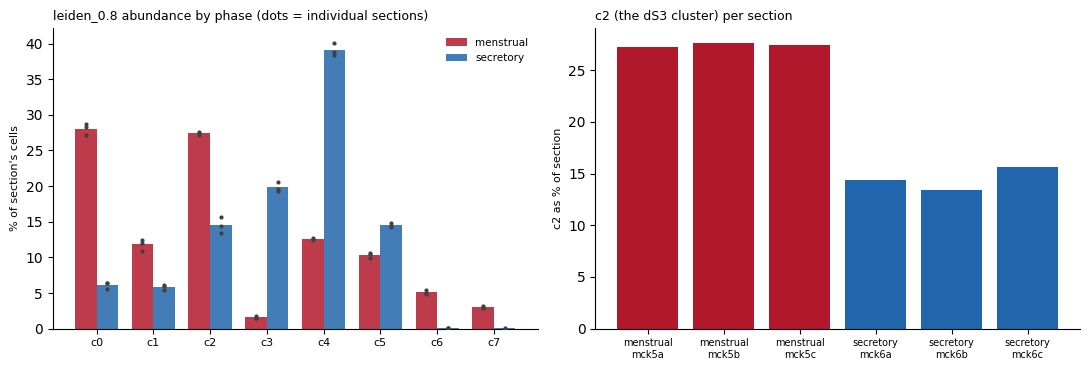

In [80]:
# Cluster abundance by timepoint and by section. Pure composition — no expression needed.
# Proportions within each section, so unequal cell yields don't drive it.
RESKEY = "leiden_0.8"
comp = (pd.crosstab(lab["sample"], lab[RESKEY], normalize="index") * 100).round(2)
comp.index.name = None
ph = lab["timepoint"].astype(str)

print(f"=== {RESKEY}: % of each section's cells ===")
print(comp.to_string())

by_ph = (pd.crosstab(ph, lab[RESKEY], normalize="index") * 100).round(2)
print(f"\n=== pooled by timepoint ===")
print(by_ph.to_string())

# per-section spread within phase — the sections are the replicate unit
sec_ph = lab.groupby("sample")["timepoint"].first()
print(f"\n=== per cluster: mean +/- spread across the 3 sections of each phase ===")
rows = []
for cl_ in comp.columns:
    m = comp[cl_].groupby(sec_ph).agg(["mean", "min", "max"])
    rows.append(dict(cluster=f"c{cl_}",
                     menstrual=f"{m.loc['menstrual','mean']:.2f}  "
                               f"[{m.loc['menstrual','min']:.2f}-{m.loc['menstrual','max']:.2f}]",
                     secretory=f"{m.loc['secretory','mean']:.2f}  "
                               f"[{m.loc['secretory','min']:.2f}-{m.loc['secretory','max']:.2f}]",
                     ratio_sec_over_men=round(m.loc['secretory','mean'] /
                                              max(m.loc['menstrual','mean'], 1e-9), 2),
                     # does every secretory section exceed every menstrual one, or do they overlap?
                     separated=bool(m.loc['secretory','min'] > m.loc['menstrual','max'] or
                                    m.loc['menstrual','min'] > m.loc['secretory','max'])))
print(pd.DataFrame(rows).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
cl_order = list(comp.columns)
w, xs = 0.38, np.arange(len(cl_order))
for i, phase in enumerate(["menstrual", "secretory"]):
    sub = comp[sec_ph == phase]
    axs[0].bar(xs + (i - .5) * w, sub.mean(), w, label=phase,
               color=["#b2182b", "#2166ac"][i], alpha=.85)
    for _, row in sub.iterrows():
        axs[0].plot(xs + (i - .5) * w, row.values, ".", color="0.25", ms=4, zorder=3)
axs[0].set_xticks(xs); axs[0].set_xticklabels([f"c{c}" for c in cl_order], fontsize=8)
axs[0].set_ylabel("% of section's cells", fontsize=8)
axs[0].set_title(f"{RESKEY} abundance by phase (dots = individual sections)", fontsize=9, loc="left")
axs[0].legend(fontsize=7.5, frameon=False)
for s in ("top", "right"): axs[0].spines[s].set_visible(False)

TARGET = "2"
t = comp[TARGET]
axs[1].bar(range(len(t)), t.values,
           color=["#b2182b" if sec_ph[i] == "menstrual" else "#2166ac" for i in t.index])
axs[1].set_xticks(range(len(t)))
axs[1].set_xticklabels([i.replace("_", "\n") for i in t.index], fontsize=7)
axs[1].set_ylabel(f"c{TARGET} as % of section", fontsize=8)
axs[1].set_title(f"c{TARGET} (the dS3 cluster) per section", fontsize=9, loc="left")
for s in ("top", "right"): axs[1].spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(f"cluster_abundance_{RESKEY}.png", dpi=300, bbox_inches="tight")

In [81]:
# c2 vs c1 — the two tied dS3 candidates, both well-populated in all six sections.
# Replaces the c7 comparison, where c7 has ~2 cells per secretory section.
n_per = pd.crosstab(lab["sample"], lab["leiden_0.8"])
print("cells per section per cluster:"); print(n_per.to_string())
print(f"\nc7 in secretory sections: {n_per.loc[n_per.index.str.startswith('secretory'), '7'].tolist()}"
      "   <- why the c7 comparison was invalid")

def paired(gene, a, b, min_cells=50):
    d = pd.DataFrame({"g": E[gene].values, "s": smp.values, "c": cl8.values})
    d = d[d.c.isin([a, b])]
    n = d.groupby(["s", "c"]).size().unstack()
    ok = n[(n[a] >= min_cells) & (n[b] >= min_cells)].index      # drop underpowered sections
    piv = d.groupby(["s", "c"]).g.mean().unstack().loc[ok]
    w = wilcoxon(piv[a], piv[b]) if len(piv) >= 5 else None
    return piv, w, len(ok), len(n)

print(f"\n=== c2 vs c1, sections with >=50 cells in both ===")
for g in ["NR2F2", "HOXA10", "STAT3", "FOXO1", "MXD4"]:
    piv, w, k, tot = paired(g, "2", "1")
    hi = int((piv["2"] > piv["1"]).sum())
    p = f"{w.pvalue:.4f}" if w else "n/a"
    print(f"{g:7s} c2 {piv['2'].mean():.4f} vs c1 {piv['1'].mean():.4f}  "
          f"ratio {piv['2'].mean()/max(piv['1'].mean(),1e-9):.2f}x  "
          f"c2>c1 in {hi}/{k} sections (of {tot})  p={p}")

# and within menstrual only, where c7 is real, so the dS1 contrast is legitimate
men = [s for s in n_per.index if s.startswith("menstrual")]
print(f"\n=== c2 vs c7, MENSTRUAL sections only (c7 = {n_per.loc[men,'7'].tolist()} cells) ===")
for g in ["NR2F2", "HOXA10", "STAT3", "FOXO1", "MXD4"]:
    d = pd.DataFrame({"g": E[g].values, "s": smp.values, "c": cl8.values})
    piv = d[d.c.isin(["2", "7"]) & d.s.isin(men)].groupby(["s", "c"]).g.mean().unstack()
    print(f"{g:7s} c7 {piv['7'].mean():.4f} vs c2 {piv['2'].mean():.4f}  "
          f"ratio {piv['7'].mean()/max(piv['2'].mean(),1e-9):.2f}x  "
          f"c7>c2 in {int((piv['7']>piv['2']).sum())}/3")

cells per section per cluster:
leiden_0.8          0     1     2     3     4     5    6    7
sample                                                       
menstrual_mck5a  2330  1027  2244   124  1050   820  401  241
menstrual_mck5b  2397   914  2312   129  1055   879  415  260
menstrual_mck5c  2037   903  2057   129   928   794  407  239
secretory_mck6a   587   496  1312  1881  3538  1303    3    2
secretory_mck6b   567   540  1197  1748  3582  1285    5    2
secretory_mck6c   302   327   845  1045  2067   801    4    2

c7 in secretory sections: [2, 2, 2]   <- why the c7 comparison was invalid

=== c2 vs c1, sections with >=50 cells in both ===
NR2F2   c2 1.5042 vs c1 1.2126  ratio 1.24x  c2>c1 in 6/6 sections (of 6)  p=0.0312
HOXA10  c2 0.3487 vs c1 0.2313  ratio 1.51x  c2>c1 in 6/6 sections (of 6)  p=0.0312
STAT3   c2 0.7924 vs c1 0.7982  ratio 0.99x  c2>c1 in 3/6 sections (of 6)  p=1.0000
FOXO1   c2 1.9964 vs c1 2.4701  ratio 0.81x  c2>c1 in 0/6 sections (of 6)  p=0.0312
MXD4    c

In [82]:
adata

AnnData object with n_obs × n_vars = 47533 × 36601
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'lineage', 'cell_type', 'subtype', 'annotation_level', 'x_um_dbscan', 'y_um_dbscan', 'cell_subtype', 'stro7_margin', 'dpt_pseudotime', 'dpt_pseudotime_provenance', 'x_um_qc', 'y_um_qc', 'spatial_qc_reason', 'tissue_section', 'leiden_0.5', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'donor', 'dpt_pseudotime_rank_normalized'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'annotation_level_colors', 'annotation_schema_version', 'display_names', 'embedding_provenance', 'embedding_provenance_note', 'hvg', 'label_colors', 'label_relabel', 'log1p', 'neighbors_scVI_100', 'spatial_outlier_fix', 'spatial_qc_push', 'timepoint_colors', 'umap', 'neighbors'
    obsm: 'X_scVI', 'X_scVI_wholetissue', 'X_spatial', 'X_umap_scVI', 'X_umap_wholetissue'
 

In [83]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wilcoxon, mannwhitneyu

PT = "dpt_pseudotime_rank_normalized"
assert PT in adata.obs, f"{PT} not in obs; available: {[c for c in adata.obs.columns if 'pseudo' in c.lower() or 'dpt' in c.lower()]}"

pt  = pd.to_numeric(adata.obs[PT], errors="coerce")
cl8 = adata.obs["leiden_0.8"].astype(str)
smp = adata.obs["sample"].astype(str)
print(f"{PT}: n={pt.notna().sum():,}/{len(pt):,}  range [{pt.min():.4f}, {pt.max():.4f}]  "
      f"median {pt.median():.4f}")

# DIRECTION. Pseudotime has no inherent polarity — it runs away from whatever cell was the root,
# so "c1 < c2" only means "c1 is earlier" if we know where the root sits. Establish it, don't assume.
for k in ("iroot", "dpt_root", "root_cell", "root"):
    if k in adata.uns:
        v = adata.uns[k]
        try:
            i = int(v)
            print(f"uns['{k}'] = {i} -> that cell is in cluster c{cl8.iloc[i]}, "
                  f"sample {smp.iloc[i]}, pseudotime {pt.iloc[i]:.4f}")
        except (TypeError, ValueError):
            print(f"uns['{k}'] = {v}")
print("\nlowest-pseudotime cells sit in:",
      cl8[pt.nsmallest(200).index].value_counts().head(3).to_dict())
print("highest-pseudotime cells sit in:",
      cl8[pt.nlargest(200).index].value_counts().head(3).to_dict())

# --- ordering of every cluster
order = pt.groupby(cl8).median().sort_values()
tbl = pd.DataFrame({"median": order.round(4),
                    "mean": pt.groupby(cl8).mean().round(4).reindex(order.index),
                    "n": cl8.value_counts().reindex(order.index)})
print(f"\n=== clusters ordered by median {PT} ===")
print(tbl.to_string())

dpt_pseudotime_rank_normalized: n=47,533/47,533  range [0.0000, 1.0000]  median 0.5000

lowest-pseudotime cells sit in: {'4': 200}
highest-pseudotime cells sit in: {'7': 195, '6': 4, '4': 1}

=== clusters ordered by median dpt_pseudotime_rank_normalized ===
            median    mean      n
leiden_0.8                       
4           0.1797  0.2243  12220
5           0.3264  0.3353   5882
3           0.4431  0.4256   5056
2           0.5747  0.5451   9967
1           0.7044  0.6756   4207
0           0.8581  0.8170   8220
7           0.9772  0.9494    746
6           0.9795  0.9733   1235


per-section MEDIAN pseudotime, c1 vs c2:
c                     1       2
s                              
menstrual_mck5a  0.6845  0.5478
menstrual_mck5b  0.6977  0.5702
menstrual_mck5c  0.6850  0.5677
secretory_mck6a  0.7344  0.5969
secretory_mck6b  0.7346  0.5976
secretory_mck6c  0.7333  0.6098

c1 mean-of-medians 0.7116   c2 0.5817   difference -0.1299
c1 < c2 in 0/6 sections   p=0.0312

cell-level: P(random c2 cell > random c1 cell) = 0.287  (0.5 = no difference; descriptive only, cells are not replicates)

c7 vs c1 (menstrual only): 0.9783 vs 0.6891, c7 < c1 in 0/3

c7 vs c2 (menstrual only): 0.9783 vs 0.5619, c7 < c2 in 0/3


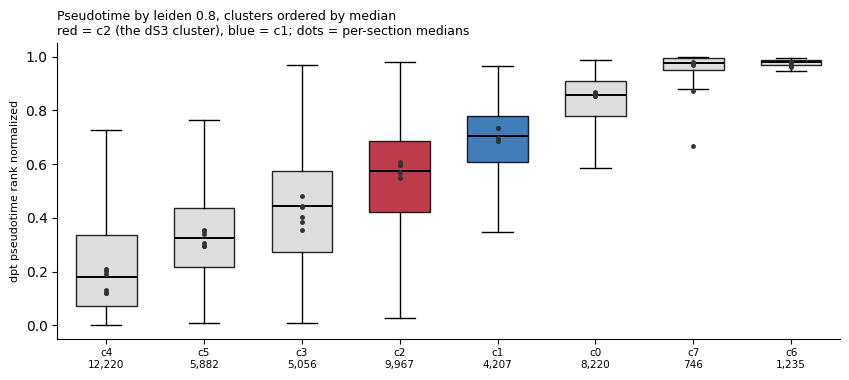

In [84]:
# --- the actual test: per-section medians, paired. Same design as the TF comparisons, so the
# 2-donor confound cannot drive it (both clusters present in every section).
def paired_pt(a, b, sections=None, min_cells=50):
    d = pd.DataFrame({"pt": pt.values, "s": smp.values, "c": cl8.values}).dropna()
    d = d[d.c.isin([a, b])]
    if sections is not None: d = d[d.s.isin(sections)]
    n   = d.groupby(["s", "c"]).size().unstack()
    ok  = n[(n[a] >= min_cells) & (n[b] >= min_cells)].index
    piv = d.groupby(["s", "c"]).pt.median().unstack().loc[ok]
    w   = wilcoxon(piv[a], piv[b]) if len(piv) >= 5 else None
    return piv, w

piv, w = paired_pt("1", "2")
print("per-section MEDIAN pseudotime, c1 vs c2:")
print(piv.round(4).to_string())
print(f"\nc1 mean-of-medians {piv['1'].mean():.4f}   c2 {piv['2'].mean():.4f}   "
      f"difference {piv['2'].mean()-piv['1'].mean():+.4f}")
print(f"c1 < c2 in {int((piv['1'] < piv['2']).sum())}/{len(piv)} sections"
      + (f"   p={w.pvalue:.4f}" if w else ""))

# cell-level, as a descriptive effect size only (47k cells -> any p is meaningless)
a = pt[(cl8 == "1")].dropna(); b = pt[(cl8 == "2")].dropna()
u = mannwhitneyu(a, b, alternative="two-sided")
print(f"\ncell-level: P(random c2 cell > random c1 cell) = {1 - u.statistic/(len(a)*len(b)):.3f}  "
      "(0.5 = no difference; descriptive only, cells are not replicates)")

# the dS1 contrast, menstrual only — c7 has 2 cells per secretory section
men = sorted(s for s in smp.unique() if s.startswith("menstrual"))
for pair in [("7", "1"), ("7", "2")]:
    p_, _ = paired_pt(*pair, sections=men)
    print(f"\nc{pair[0]} vs c{pair[1]} (menstrual only): "
          f"{p_[pair[0]].mean():.4f} vs {p_[pair[1]].mean():.4f}, "
          f"c{pair[0]} < c{pair[1]} in {int((p_[pair[0]] < p_[pair[1]]).sum())}/{len(p_)}")

# --- distributions
fig, ax = plt.subplots(figsize=(8.6, 3.9))
cl_order = list(order.index)
data = [pt[(cl8 == c)].dropna().values for c in cl_order]
bp = ax.boxplot(data, positions=range(len(cl_order)), widths=.62, showfliers=False,
                patch_artist=True, medianprops=dict(color="black", lw=1.4))
for patch, c in zip(bp["boxes"], cl_order):
    patch.set_facecolor("#b2182b" if c == "2" else "#2166ac" if c == "1" else "#d9d9d9")
    patch.set_alpha(.85)
for j, c in enumerate(cl_order):                      # per-section medians = the replicate unit
    m = pt[(cl8 == c)].groupby(smp[(cl8 == c)]).median()
    ax.plot(np.full(len(m), j), m.values, ".", color="0.2", ms=5, zorder=3)
ax.set_xticks(range(len(cl_order)))
ax.set_xticklabels([f"c{c}\n{tbl.loc[c,'n']:,}" for c in cl_order], fontsize=7.5)
ax.set_ylabel(PT.replace("_", " "), fontsize=8)
ax.set_title("Pseudotime by leiden 0.8, clusters ordered by median\n"
             "red = c2 (the dS3 cluster), blue = c1; dots = per-section medians",
             fontsize=9, loc="left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig("pseudotime_by_leiden08.png", dpi=300, bbox_inches="tight")

In [85]:
# Which end of the pseudotime axis is decidualised? IGFBP1 and PRL are the canonical markers;
# whichever direction they increase in IS the decidualisation direction. No assumption needed.
from scipy.stats import spearmanr

ANCHOR = ["IGFBP1", "PRL", "MMP10", "MMP3", "LEFTY2",   # decidualisation
          "HOXA10", "NR2F2", "PGR",                      # stromal identity / dS3-associated
          "MKI67", "TOP2A"]                              # proliferation, for the progenitor end
anch = [g for g in ANCHOR if g in adata.var_names]
print("missing:", [g for g in ANCHOR if g not in adata.var_names] or "none")

Xa = adata[:, anch].layers[LAYER] if LAYER else adata[:, anch].X
Xa = Xa.toarray() if sp.issparse(Xa) else np.asarray(Xa)
Ea = pd.DataFrame(Xa, index=adata.obs_names, columns=anch)

ok = pt.notna().values
rows = []
for g in anch:
    rho = spearmanr(pt[ok], Ea[g].values[ok]).statistic
    # per-section, so a donor effect can't set the sign
    per = []
    for s in sorted(smp.unique()):
        m = ok & (smp == s).values
        per.append(spearmanr(pt[m], Ea[g].values[m]).statistic)
    rows.append(dict(gene=g, rho_pooled=round(rho, 3),
                     rho_per_section_mean=round(np.mean(per), 3),
                     sections_same_sign=f"{int(np.sum(np.sign(per) == np.sign(rho)))}/6",
                     pct_cells_pos=round(100 * (Ea[g] > 0).mean(), 1)))
D = pd.DataFrame(rows)
print("\n=== correlation of pseudotime with anchor genes ===")
print(D.to_string(index=False))

dec = D[D.gene.isin(["IGFBP1", "PRL", "MMP10", "MMP3", "LEFTY2"])].rho_pooled.mean()
pro = D[D.gene.isin(["MKI67", "TOP2A"])].rho_pooled.mean()
print(f"\nmean rho with decidualisation markers: {dec:+.3f}")
print(f"mean rho with proliferation markers:  {pro:+.3f}")
print("\nDIRECTION:", "HIGH pseudotime = MORE decidualised (Reading A)" if dec > 0
      else "LOW pseudotime = MORE decidualised (Reading B) — the axis runs decidual -> stromal")

# and where each cluster sits, with its decidual marker level, so the two agree or don't
med_pt = pt.groupby(cl8).median()
dec_g  = [g for g in ["IGFBP1", "PRL", "MMP10"] if g in anch]
summary = pd.DataFrame({"median_pt": med_pt.round(4),
                        **{g: Ea[g].groupby(cl8).mean().round(4) for g in dec_g}})
summary["n"] = cl8.value_counts()
print("\n=== per cluster: pseudotime vs decidualisation markers ===")
print(summary.sort_values("median_pt").to_string())

missing: none

=== correlation of pseudotime with anchor genes ===
  gene  rho_pooled  rho_per_section_mean sections_same_sign  pct_cells_pos
IGFBP1       0.225                 0.227                6/6            3.9
   PRL       0.095                 0.083                6/6            0.7
 MMP10       0.621                 0.554                6/6           23.0
  MMP3       0.374                 0.319                6/6            8.1
LEFTY2       0.313                 0.231                6/6           27.6
HOXA10      -0.017                -0.014                3/6           18.8
 NR2F2       0.026                -0.018                3/6           63.5
   PGR      -0.182                -0.061                3/6           73.8
 MKI67      -0.004                   NaN                2/6            0.0
 TOP2A       0.023                 0.016                5/6            0.2

mean rho with decidualisation markers: +0.326
mean rho with proliferation markers:  +0.009

DIRECTION: HIGH

/tmp/ipykernel_3784324/4068958991.py:23: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  per.append(spearmanr(pt[m], Ea[g].values[m]).statistic)
